# Практическая работа: кредитный скоринг заёмщиков с помощью машинного обучения №1 

## 0. Подключение библиотек и настройки

In [ ]:
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from cycler import cycler
from IPython.display import display, Markdown

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, RandomizedSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, VotingClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import (roc_auc_score, roc_curve, average_precision_score, brier_score_loss,
                             log_loss, confusion_matrix, classification_report,
                             accuracy_score, precision_score, recall_score, f1_score)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

# --- единый стиль графиков ---
C = {'blue': '#2a78d6', 'orange': '#eb6834', 'aqua': '#1baf7a', 'yellow': '#eda100',
     'magenta': '#e87ba4', 'green': "#32A532", 'violet': '#6250d6', 'red': '#e34948',
     'ink': '#0b0b0b', 'ink2': '#52514e', 'muted': '#8a8984', 'grid': '#e6e5e0', 'surface': '#fcfcfb'}
STATUS = {'Одобрить': '#0ca30c', 'Доп. проверка': '#fab219', 'Отклонить': '#d03b3b'}
CLASS_COLORS = {0: C['blue'], 1: C['orange']}    
CLASS_NAMES = {0: 'Надёжный (0)', 1: 'Дефолт (1)'}

plt.rcParams.update({
    'figure.facecolor': C['surface'], 'axes.facecolor': C['surface'], 'savefig.facecolor': C['surface'],
    'axes.edgecolor': '#c9c8c2', 'axes.labelcolor': C['ink2'], 'text.color': C['ink'],
    'xtick.color': C['ink2'], 'ytick.color': C['ink2'],
    'axes.grid': True, 'grid.color': C['grid'], 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.prop_cycle': cycler(color=[C[k] for k in ['blue', 'orange', 'aqua', 'yellow', 'magenta', 'green', 'violet', 'red']]),
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'font.size': 10, 'legend.frameon': False, 'lines.linewidth': 2, 'figure.dpi': 110,
})
DIVERGING = LinearSegmentedColormap.from_list('div', [C['blue'], '#f0efec', C['red']])
SEQUENTIAL = LinearSegmentedColormap.from_list('seq', ['#f3f7fd', '#86b6ef', '#2a78d6', '#104281'])

def money(v):
    # формат денежной суммы: 1 234 567
    return f'{v:,.0f}'.replace(',', ' ')

## 1. Выбор датасета

Используется открытый датасет **Credit Risk Dataset** с Kaggle ([laotse/credit-risk-dataset](https://www.kaggle.com/datasets/laotse/credit-risk-dataset)) - данные о потребительских кредитах, аналогичные данным кредитного бюро. Каждая строка - один выданный кредит, целевая переменная `loan_status` показывает, допустил ли заёмщик дефолт.

In [50]:
DATA_PATH = Path('credit_risk_dataset.csv')
MIRROR_URL = 'https://raw.githubusercontent.com/suhasbp37/credit-risk-dataset-analytics/main/credit_risk_dataset.csv'

if DATA_PATH.exists():
    df_raw = pd.read_csv(DATA_PATH)
else:
    df_raw = pd.read_csv(MIRROR_URL)
    df_raw.to_csv(DATA_PATH, index=False)

TARGET = 'loan_status'
NUM_COLS = ['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
            'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']
CAT_COLS = ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']
ALL_FEATURES = NUM_COLS + CAT_COLS

RU = {'person_age': 'Возраст', 'person_income': 'Годовой доход', 'person_home_ownership': 'Тип жилья',
      'person_emp_length': 'Стаж работы', 'loan_intent': 'Цель кредита', 'loan_grade': 'Кредитный грейд',
      'loan_amnt': 'Сумма кредита', 'loan_int_rate': 'Процентная ставка',
      'loan_percent_income': 'Кредит / доход', 'cb_person_default_on_file': 'Дефолт в истории',
      'cb_person_cred_hist_length': 'Длина кред. истории', 'loan_status': 'Дефолт (цель)'}

print(f'Загружено: {df_raw.shape[0]:,} строк × {df_raw.shape[1]} столбцов'.replace(',', ' '))
df_raw.head()

Загружено: 32 581 строк × 12 столбцов


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [51]:
from pathlib import Path
import zipfile

import numpy as np
import pandas as pd

ORIG_COLS = {
    0: 'credit_score', 1: 'first_payment_date', 2: 'first_time_homebuyer', 3: 'maturity_date',
    4: 'msa', 5: 'mi_pct', 6: 'num_units', 7: 'occupancy_status', 8: 'cltv', 9: 'dti',
    10: 'orig_upb', 11: 'ltv', 12: 'orig_interest_rate', 13: 'channel', 14: 'ppm_flag',
    15: 'amortization_type', 16: 'property_state', 17: 'property_type', 18: 'postal_code',
    19: 'loan_id', 20: 'loan_purpose', 21: 'orig_loan_term', 22: 'num_borrowers',
}
PERF_COLS = {
    0: 'loan_id', 1: 'period', 2: 'current_upb', 3: 'dlq_status', 4: 'loan_age',
    8: 'zero_balance_code', 9: 'zero_balance_date', 21: 'actual_loss', 26: 'zb_removal_upb',
}

ORIG_NUMERIC = ['credit_score', 'mi_pct', 'num_units', 'cltv', 'dti', 'orig_upb', 'ltv',
                'orig_interest_rate', 'orig_loan_term', 'num_borrowers']

MISSING_CODES = {
    'credit_score': [9999], 'dti': [999], 'ltv': [999], 'cltv': [999], 'mi_pct': [999],
    'num_units': [99], 'num_borrowers': [99],
    'first_time_homebuyer': ['9'], 'occupancy_status': ['9'], 'channel': ['9'],
    'property_type': ['99'], 'loan_purpose': ['9'],
}

CREDIT_EVENT_ZB = {'02', '03', '09'}


def _open(path, kind):
    """Открывает sample_orig/sample_perf из zip-архива или из распакованной папки."""
    path = Path(path)
    if path.suffix == '.zip':
        zf = zipfile.ZipFile(path)
        name = next(n for n in zf.namelist() if f'_{kind}_' in Path(n).name)
        return zf.open(name)
    if path.is_dir():
        return open(next(path.glob(f'*_{kind}_*.txt')), 'rb')
    return open(path, 'rb')


def load_orig(path):
    with _open(path, 'orig') as f:
        d = pd.read_csv(f, sep='|', header=None, usecols=list(ORIG_COLS), dtype=str)
    d = d.rename(columns=ORIG_COLS)
    for c in d.columns:
        d[c] = d[c].str.strip()
    for c in ORIG_NUMERIC:
        d[c] = pd.to_numeric(d[c], errors='coerce')
    for c, codes in MISSING_CODES.items():
        d[c] = d[c].where(~d[c].isin(codes))
    d['first_payment'] = pd.to_datetime(d['first_payment_date'], format='%Y%m', errors='coerce')
    d['vintage'] = d['first_payment'].dt.year
    return d


def _perf_summary(path, horizon, chunksize=1_000_000):
    """Сводит помесячную историю к одной строке на кредит, читая файл частями."""
    parts, disposals = [], []
    with _open(path, 'perf') as f:
        for ch in pd.read_csv(f, sep='|', header=None, usecols=list(PERF_COLS), dtype=str,
                              chunksize=chunksize):
            ch = ch.rename(columns=PERF_COLS)
            ch['dlq_status'] = ch['dlq_status'].str.strip()
            ch['zero_balance_code'] = ch['zero_balance_code'].str.strip()
            ch['loan_age'] = pd.to_numeric(ch['loan_age'], errors='coerce')
            dlq_num = pd.to_numeric(ch['dlq_status'], errors='coerce')

            in_window = ch['loan_age'] <= horizon
            event = ((dlq_num >= 3) | (ch['dlq_status'] == 'RA')
                     | ch['zero_balance_code'].isin(CREDIT_EVENT_ZB))
            closed = ch['zero_balance_code'].notna() & (ch['zero_balance_code'] != '')
            parts.append(pd.DataFrame({
                'loan_id': ch['loan_id'],
                'default': (event & in_window).astype(int),
                'closed_in_window': (closed & in_window).astype(int),
                'max_age': ch['loan_age'],
            }).groupby('loan_id').max())

            disp = ch[ch['zero_balance_code'].isin(CREDIT_EVENT_ZB)].copy()
            if len(disp):
                for c in ['actual_loss', 'zb_removal_upb', 'current_upb']:
                    disp[c] = pd.to_numeric(disp[c], errors='coerce')
                disposals.append(disp[['loan_id', 'period', 'zero_balance_code', 'loan_age',
                                       'actual_loss', 'zb_removal_upb', 'current_upb']])
    summary = pd.concat(parts).groupby(level=0).max()
    disposals = pd.concat(disposals, ignore_index=True) if disposals else pd.DataFrame()
    return summary, disposals


def load_vintage(path, horizon=24):
    """Один sample_YYYY: признаки при выдаче + целевая переменная default.

    default = 1, если в первые `horizon` месяцев была просрочка 90+ дней, REO
    или кредит закрыт с кредитным событием (коды 02, 03, 09).
    Кредиты, у которых окно ещё не закончилось и дефолта не было, исключаются
    (их исход пока неизвестен).
    """
    orig = load_orig(path)
    summary, disposals = _perf_summary(path, horizon)
    d = orig.merge(summary, left_on='loan_id', right_index=True, how='inner')
    observed = (d['default'] == 1) | (d['closed_in_window'] == 1) | (d['max_age'] >= horizon)
    d['observed'] = observed
    return d, disposals


def load_vintages(paths, horizon=24, keep_unobserved=False):
    """Несколько лет выдачи сразу. Возвращает (кредиты, закрытия с кредитным событием)."""
    loans, disposals = [], []
    for p in paths:
        d, disp = load_vintage(p, horizon)
        n_all = len(d)
        if not keep_unobserved:
            d = d[d['observed']]
        fmt = lambda n: f'{n:,}'.replace(',', ' ')
        print(f'{Path(p).name}: кредитов {fmt(n_all)}, с полным окном {fmt(len(d))}, '
              f'доля дефолтов {d["default"].mean():.2%}')
        loans.append(d)
        disposals.append(disp)
    loans = pd.concat(loans, ignore_index=True)
    disposals = pd.concat([x for x in disposals if len(x)], ignore_index=True) if any(len(x) for x in disposals) else pd.DataFrame()
    return loans, disposals


def estimate_lgd(disposals, min_obs=30):
    """LGD по фактическим потерям: потеря / остаток долга на момент закрытия.

    Знак Actual Loss различается между версиями формата, поэтому он определяется по медиане.
    Возвращает Series LGD по кредитам; если наблюдений меньше min_obs - печатает предупреждение.
    """
    d = disposals.dropna(subset=['actual_loss'])
    upb = d['zb_removal_upb'].where(d['zb_removal_upb'] > 0, d['current_upb'])
    d = d[upb > 0]
    upb = upb[upb > 0]
    loss = d['actual_loss'] if d['actual_loss'].median() >= 0 else -d['actual_loss']
    lgd = (loss / upb).clip(0, 1.5)
    if len(lgd) < min_obs:
        print(f'Внимание: всего {len(lgd)} закрытий с известной потерей - LGD ненадёжен, '
              f'возьми более ранние годы выдачи или задай LGD константой.')
    return lgd

## 2. Описание датасета: структура и статистика
### 2.1 Структура

In [52]:
structure = pd.DataFrame(index=df_raw.columns)
structure['Описание'] = [RU[c] for c in df_raw.columns]
structure['Тип данных'] = df_raw.dtypes.astype(str).values
structure['Группа'] = ['числовой' if c in NUM_COLS else ('целевая' if c == TARGET else 'категориальный') for c in df_raw.columns]
structure['Уникальных значений'] = df_raw.nunique().values
structure['Пропусков'] = df_raw.isna().sum().values
structure['% пропусков'] = (df_raw.isna().mean() * 100).round(2).values
display(structure)

print(f'Числовых признаков: {len(NUM_COLS)}, категориальных: {len(CAT_COLS)}, целевая переменная: {TARGET}')
print(f'Полных дубликатов строк: {df_raw.duplicated().sum()}')

,Описание,Тип данных,Группа,Уникальных значений,Пропусков,% пропусков
person_age,Возраст,int64,числовой,58,0,0.00
person_income,Годовой доход,int64,числовой,4295,0,0.00
person_home_ownership,Тип жилья,str,категориальный,4,0,0.00
person_emp_length,Стаж работы,float64,числовой,36,895,2.75
loan_intent,Цель кредита,str,категориальный,6,0,0.00
loan_grade,Кредитный грейд,str,категориальный,7,0,0.00
loan_amnt,Сумма кредита,int64,числовой,753,0,0.00
loan_int_rate,Процентная ставка,float64,числовой,348,3116,9.56
loan_status,Дефолт (цель),int64,целевая,2,0,0.00
loan_percent_income,Кредит / доход,float64,числовой,77,0,0.00


Числовых признаков: 7, категориальных: 4, целевая переменная: loan_status
Полных дубликатов строк: 165


### 2.2 Описательная статистика числовых признаков

In [53]:
desc = df_raw[NUM_COLS].describe(percentiles=[.01, .25, .5, .75, .99]).T
desc.index = [RU[c] for c in desc.index]
desc.round(2)

,count,mean,std,min,1%,25%,50%,75%,99%,max
Возраст,32581.0,27.73,6.35,20.00,21.00,23.00,26.00,30.00,50.00,144.00
Годовой доход,32581.0,66074.85,61983.12,4000.00,14400.00,38500.00,55000.00,79200.00,225200.00,6000000.00
Стаж работы,31686.0,4.79,4.14,0.00,0.00,2.00,4.00,7.00,18.00,123.00
Сумма кредита,32581.0,9589.37,6322.09,500.00,1000.00,5000.00,8000.00,12200.00,29800.00,35000.00
Процентная ставка,29465.0,11.01,3.24,5.42,5.42,7.90,10.99,13.47,18.62,23.22
Кредит / доход,32581.0,0.17,0.11,0.00,0.02,0.09,0.15,0.23,0.50,0.83
Длина кред. истории,32581.0,5.80,4.06,2.00,2.00,3.00,4.00,8.00,17.00,30.00


### 2.3 Категориальные признаки: частоты и доля дефолтов в каждой категории

In [54]:
for col in CAT_COLS:
    t = (df_raw.groupby(col)[TARGET]
         .agg(Количество='size', Доля_дефолтов='mean')
         .assign(Доля_выборки=lambda d: d['Количество'] / d['Количество'].sum()))
    t = t[['Количество', 'Доля_выборки', 'Доля_дефолтов']].round(3)
    display(Markdown(f'**{RU[col]}** (`{col}`)'))
    display(t)

**Тип жилья** (`person_home_ownership`)

,Количество,Доля_выборки,Доля_дефолтов
person_home_ownership,,,
MORTGAGE,13444,0.413,0.126
OTHER,107,0.003,0.308
OWN,2584,0.079,0.075
RENT,16446,0.505,0.316


**Цель кредита** (`loan_intent`)

,Количество,Доля_выборки,Доля_дефолтов
loan_intent,,,
DEBTCONSOLIDATION,5212,0.160,0.286
EDUCATION,6453,0.198,0.172
HOMEIMPROVEMENT,3605,0.111,0.261
MEDICAL,6071,0.186,0.267
PERSONAL,5521,0.169,0.199
VENTURE,5719,0.176,0.148


**Кредитный грейд** (`loan_grade`)

,Количество,Доля_выборки,Доля_дефолтов
loan_grade,,,
A,10777,0.331,0.100
B,10451,0.321,0.163
C,6458,0.198,0.207
D,3626,0.111,0.590
E,964,0.030,0.644
F,241,0.007,0.705
G,64,0.002,0.984


**Дефолт в истории** (`cb_person_default_on_file`)

,Количество,Доля_выборки,Доля_дефолтов
cb_person_default_on_file,,,
N,26836,0.824,0.184
Y,5745,0.176,0.378


### 2.4 Баланс классов целевой переменной

,Количество,Доля
Надёжный (0),25473,0.7818
Дефолт (1),7108,0.2182


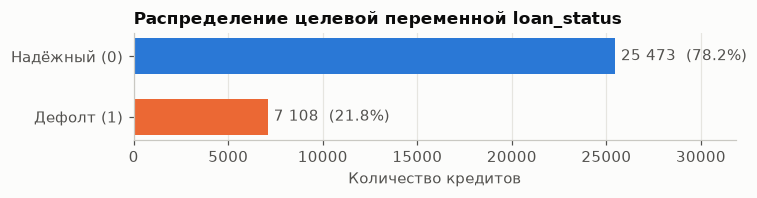

In [55]:
counts = df_raw[TARGET].value_counts().sort_index()
shares = counts / counts.sum()
display(pd.DataFrame({'Количество': counts, 'Доля': shares.round(4)}, index=[0, 1]).rename(index=CLASS_NAMES))

fig, ax = plt.subplots(figsize=(7, 1.9))
ax.barh([CLASS_NAMES[i] for i in counts.index], counts.values, color=[CLASS_COLORS[i] for i in counts.index], height=0.6)
for i, (n, s) in enumerate(zip(counts.values, shares.values)):
    ax.text(n + 300, i, f'{money(n)}  ({s:.1%})', va='center', color=C['ink2'])
ax.set_xlim(0, counts.max() * 1.25); ax.invert_yaxis(); ax.grid(axis='y', visible=False)
ax.set_title('Распределение целевой переменной loan_status'); ax.set_xlabel('Количество кредитов')
plt.tight_layout(); plt.show()

### 2.5 Распределения числовых признаков по классам
Для наглядности значения обрезаны по 1-му и 99-му перцентилям (только на графике, данные не меняются).

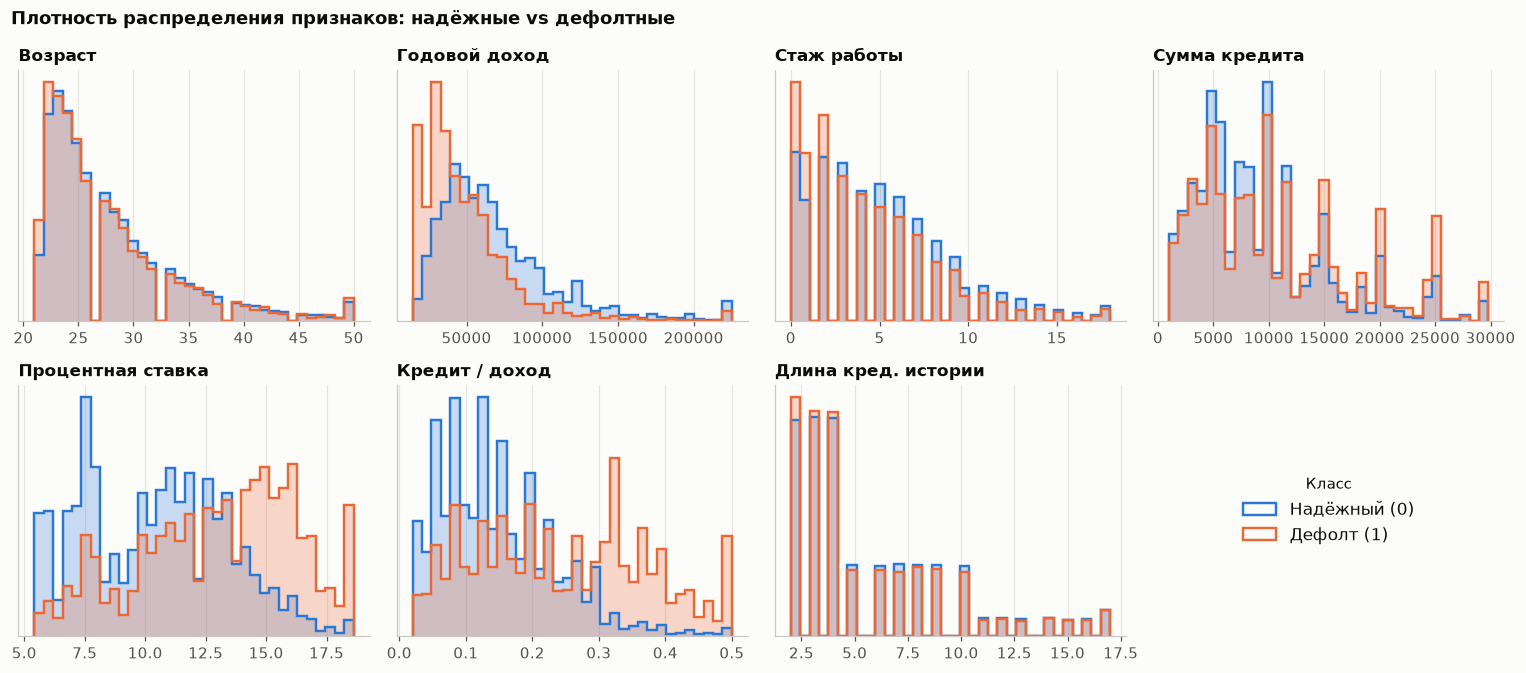

In [56]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6.2))
for ax, col in zip(axes.flat, NUM_COLS):
    lo, hi = df_raw[col].quantile([.01, .99])
    bins = np.linspace(lo, hi, 35)
    for cls in [0, 1]:
        v = df_raw.loc[df_raw[TARGET] == cls, col].dropna().clip(lo, hi)
        ax.hist(v, bins=bins, density=True, histtype='stepfilled', alpha=0.25, color=CLASS_COLORS[cls])
        ax.hist(v, bins=bins, density=True, histtype='step', linewidth=1.6, color=CLASS_COLORS[cls], label=CLASS_NAMES[cls])
    ax.set_title(RU[col]); ax.set_yticks([])
axes.flat[-1].axis('off')
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles, labels, loc='center', fontsize=11, title='Класс')
fig.suptitle('Плотность распределения признаков: надёжные vs дефолтные', x=0.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.show()

### 2.6 Доля дефолтов по категориальным признакам
Пунктир - средняя доля дефолтов по всей выборке.

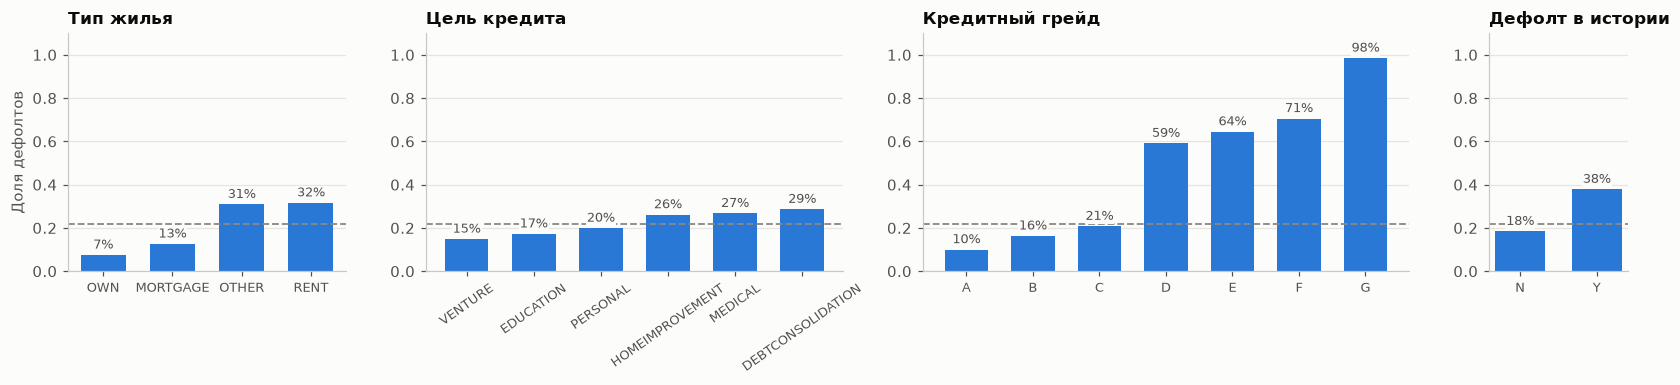

In [57]:
base_rate = df_raw[TARGET].mean()
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), gridspec_kw={'width_ratios': [4, 6, 7, 2]})
for ax, col in zip(axes, CAT_COLS):
    r = df_raw.groupby(col)[TARGET].mean()
    if col != 'loan_grade':
        r = r.sort_values()
    ax.bar(r.index.astype(str), r.values, color=C['blue'], width=0.65)
    ax.axhline(base_rate, color=C['muted'], linestyle='--', linewidth=1.2)
    for x, v in enumerate(r.values):
        ax.text(x, v + 0.03, f'{v:.0%}', ha='center', fontsize=8.5, color=C['ink2'],
                bbox=dict(facecolor=C['surface'], edgecolor='none', pad=0.6))
    ax.set_title(RU[col]); ax.set_ylim(0, 1.1); ax.grid(axis='x', visible=False)
    ax.tick_params(axis='x', rotation=35 if col == 'loan_intent' else 0, labelsize=8.5)
axes[0].set_ylabel('Доля дефолтов')
plt.tight_layout(); plt.show()

### 2.7 Корреляции признаков
Для расчёта грейд закодирован порядково (A = 0 … G = 6), наличие дефолта в истории - 0/1.

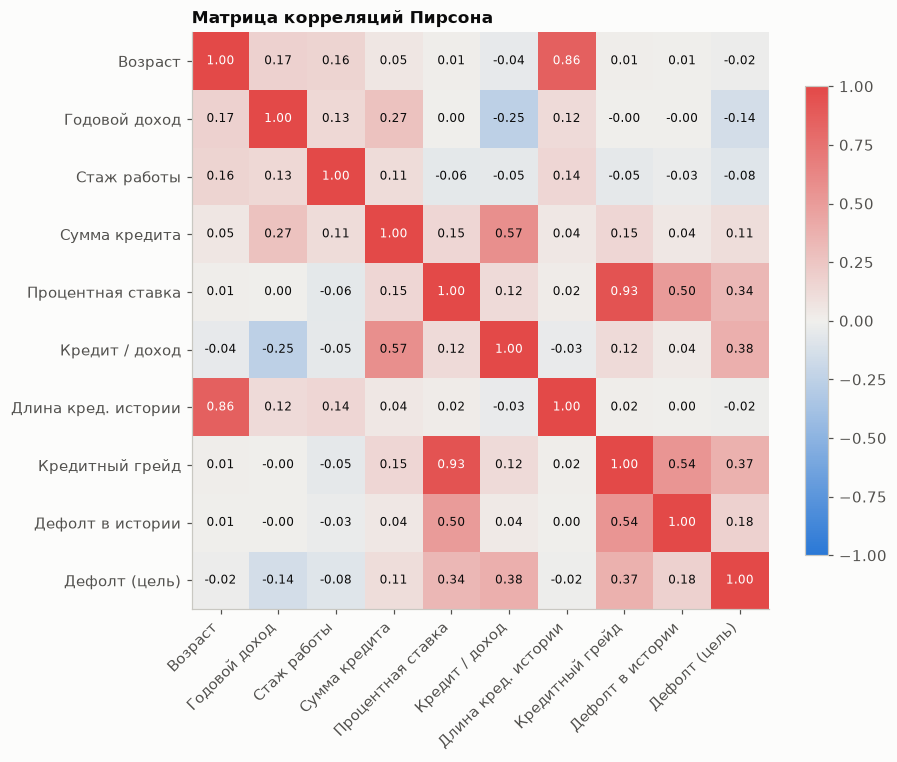

Корреляция признаков с дефолтом (по убыванию модуля):
Кредит / доход         0.379
Кредитный грейд        0.373
Процентная ставка      0.335
Дефолт в истории       0.179
Годовой доход         -0.144
Сумма кредита          0.105
Стаж работы           -0.082
Возраст               -0.022
Длина кред. истории   -0.016


In [58]:
eda = df_raw.copy()
eda['loan_grade'] = eda['loan_grade'].map({g: i for i, g in enumerate('ABCDEFG')})
eda['cb_person_default_on_file'] = (eda['cb_person_default_on_file'] == 'Y').astype(int)
corr_cols = NUM_COLS + ['loan_grade', 'cb_person_default_on_file', TARGET]
corr = eda[corr_cols].corr()

fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr.values, cmap=DIVERGING, vmin=-1, vmax=1)
labels = [RU[c] for c in corr_cols]
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=45, ha='right')
ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels); ax.grid(False)
for i in range(len(labels)):
    for j in range(len(labels)):
        v = corr.values[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=8, color='white' if abs(v) > 0.6 else C['ink'])
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title('Матрица корреляций Пирсона')
plt.tight_layout(); plt.show()

print('Корреляция признаков с дефолтом (по убыванию модуля):')
print(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).rename(RU).round(3).to_string())

**Наблюдения по датасету**

* В данных 32 581 кредит и 11 признаков; дефолтных кредитов около 22 % - классы несбалансированы, поэтому accuracy не подходит как основная метрика, используем ROC-AUC.
* Пропуски есть в двух признаках: `loan_int_rate` (≈ 9,6 %) и `person_emp_length` (≈ 2,7 %). Найдено 165 полных дубликатов.
* Есть явные аномалии: максимальный возраст 144 года и стаж 123 года - это ошибки ввода.
* Уже на этапе описательного анализа видно, что риск дефолта сильно растёт с ухудшением грейда (A ≈ 10 % → G ≈ 98 %), при аренде жилья (≈ 32 % против ≈ 7 % у собственников), при наличии дефолта в истории и при высокой доле кредита в доходе.
* Сильно коррелируют между собой: возраст и длина кредитной истории (0,86), грейд и процентная ставка (0,93) - это нужно учесть при отборе признаков.

## 3. Предобработка данных

Шаги:
1. удаление полных дубликатов;
2. удаление аномальных записей (возраст > 100 лет, стаж > 60 лет);
3. разбиение на обучающую (75 %) и тестовую (25 %) выборки **со стратификацией** по целевой переменной - до заполнения пропусков, чтобы статистики для заполнения считались только по обучающей выборке и не было утечки данных;
4. заполнение пропусков: стаж - медианой, ставка - **медианой внутри своего грейда** (ставка почти полностью определяется грейдом);
5. кодирование категорий: грейд - порядково (A = 0 … G = 6), `cb_person_default_on_file` - 0/1, тип жилья и цель кредита - one-hot.

Масштабирование признаков нужно только логистической регрессии, поэтому оно выполняется внутри её пайплайна; деревьям оно не требуется.

In [59]:
df = df_raw.drop_duplicates().copy()
print(f'Удалено дубликатов: {len(df_raw) - len(df)}')

anomaly = (df['person_age'] > 100) | (df['person_emp_length'] > 60)
print(f'Аномальных записей: {anomaly.sum()}')
display(df[anomaly])
df = df[~anomaly].reset_index(drop=True)
print(f'Итоговый размер: {df.shape[0]:,} строк; доля дефолтов: {df[TARGET].mean():.2%}'.replace(',', ' '))

Удалено дубликатов: 165
Аномальных записей: 7


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
81,144,250000,RENT,4.0,VENTURE,C,4800,13.57,0,0.02,N,3
183,144,200000,MORTGAGE,4.0,EDUCATION,B,6000,11.86,0,0.03,N,2
210,21,192000,MORTGAGE,123.0,VENTURE,A,20000,6.54,0,0.10,N,4
575,123,80004,RENT,2.0,EDUCATION,B,20400,10.25,0,0.25,N,3
747,123,78000,RENT,7.0,VENTURE,B,20000,NaN,0,0.26,N,4
32297,144,6000000,MORTGAGE,12.0,PERSONAL,C,5000,12.73,0,0.00,N,25


Итоговый размер: 32 409 строк; доля дефолтов: 21.87%


Проверим, связаны ли пропуски ставки с дефолтом: если доля дефолтов среди пропусков близка к средней, пропуски можно заполнять без отдельного флага.

In [60]:
print(f"Доля дефолтов, где ставка пропущена: {df.loc[df['loan_int_rate'].isna(), TARGET].mean():.2%}")
print(f"Доля дефолтов, где ставка известна:  {df.loc[df['loan_int_rate'].notna(), TARGET].mean():.2%}")
print(f"Доля дефолтов, где стаж пропущен:    {df.loc[df['person_emp_length'].isna(), TARGET].mean():.2%}")

Доля дефолтов, где ставка пропущена: 20.72%
Доля дефолтов, где ставка известна:  21.99%
Доля дефолтов, где стаж пропущен:    31.68%


In [61]:
X = df.drop(columns=TARGET)
y = df[TARGET]
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

print(f'Обучающая выборка: {len(X_train_raw):,} (дефолтов {y_train.mean():.2%})'.replace(',', ' '))
print(f'Тестовая выборка:  {len(X_test_raw):,} (дефолтов {y_test.mean():.2%})'.replace(',', ' '))

Обучающая выборка: 24 306 (дефолтов 21.87%)
Тестовая выборка:  8 103 (дефолтов 21.87%)


In [62]:
GRADE_ORDER = list('ABCDEFG')

class CreditPreprocessor(BaseEstimator, TransformerMixin):

    def __init__(self, features=None):
        self.features = features

    def fit(self, X, y=None):
        self.emp_median_ = X['person_emp_length'].median()
        self.rate_by_grade_ = X.groupby('loan_grade')['loan_int_rate'].median()
        self.columns_ = None
        self.columns_ = self.transform(X).columns
        return self

    def transform(self, X):
        feats = self.features or ALL_FEATURES
        d = X[feats].copy()
        if 'person_emp_length' in d:
            d['person_emp_length'] = d['person_emp_length'].fillna(self.emp_median_)
        if 'loan_int_rate' in d:
            d['loan_int_rate'] = d['loan_int_rate'].fillna(X['loan_grade'].map(self.rate_by_grade_))
        if 'loan_grade' in d:
            d['loan_grade'] = d['loan_grade'].map({g: i for i, g in enumerate(GRADE_ORDER)}).astype(int)
        if 'cb_person_default_on_file' in d:
            d['cb_person_default_on_file'] = (d['cb_person_default_on_file'] == 'Y').astype(int)
        ohe = [c for c in ['person_home_ownership', 'loan_intent'] if c in d]
        d = pd.get_dummies(d, columns=ohe, dtype=int)
        if self.columns_ is not None:
            d = d.reindex(columns=self.columns_, fill_value=0)
        return d.astype(float)

prep = CreditPreprocessor().fit(X_train_raw)
X_train = prep.transform(X_train_raw)
X_test = prep.transform(X_test_raw)

print('Медиана стажа (train):', prep.emp_median_)
print('Медианная ставка по грейдам (train):')
print(prep.rate_by_grade_.round(2).to_string())
print(f'\nПропусков после обработки: train {int(X_train.isna().sum().sum())}, test {int(X_test.isna().sum().sum())}')
print(f'Признаков после кодирования: {X_train.shape[1]}')
X_train.head()

Медиана стажа (train): 4.0
Медианная ставка по грейдам (train):
loan_grade
A     7.49
B    10.99
C    13.48
D    15.31
E    16.77
F    18.53
G    20.11

Пропусков после обработки: train 0, test 0
Признаков после кодирования: 19


,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,loan_grade,cb_person_default_on_file,person_home_ownership_MORTGAGE,person_home_ownership_OTHER,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_DEBTCONSOLIDATION,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE
17502,23.0,92000.0,7.0,18000.0,12.68,0.20,2.0,2.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
6411,21.0,39900.0,3.0,6000.0,11.49,0.15,3.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0
9130,26.0,34000.0,8.0,5050.0,16.89,0.15,4.0,3.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
15606,23.0,85000.0,7.0,15000.0,14.59,0.18,4.0,3.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
31540,40.0,22800.0,0.0,1500.0,7.29,0.07,16.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0


## 4. Выявление главных признаков

Используем три независимых взгляда на важность признаков (все считаются **только на обучающей выборке**):

1. **Information Value (IV)** - классический для кредитного скоринга показатель разделяющей силы признака на основе WoE (*Weight of Evidence*):
   $WoE_i = \ln\dfrac{\%\,\text{надёжных}_i}{\%\,\text{дефолтных}_i}$, $IV = \sum_i (\%\,\text{надёжных}_i - \%\,\text{дефолтных}_i)\cdot WoE_i$.
   Шкала: < 0,02 - бесполезный, 0,02–0,1 - слабый, 0,1–0,3 - средний, 0,3–0,5 - сильный, > 0,5 - очень сильный (стоит проверить на утечку).
2. **Взаимная информация (Mutual Information)** - улавливает и нелинейные зависимости.
3. **Перестановочная важность (permutation importance)** предварительной модели градиентного бустинга на валидационной части обучающей выборки: на сколько падает ROC-AUC, если перемешать признак.

,Признак,IV,Сила
loan_grade,Кредитный грейд,0.888,очень сильный
loan_percent_income,Кредит / доход,0.869,очень сильный
loan_int_rate,Процентная ставка,0.676,очень сильный
person_income,Годовой доход,0.468,сильный
person_home_ownership,Тип жилья,0.384,сильный
cb_person_default_on_file,Дефолт в истории,0.155,средний
loan_intent,Цель кредита,0.091,слабый
loan_amnt,Сумма кредита,0.085,слабый
person_emp_length,Стаж работы,0.070,слабый
person_age,Возраст,0.011,бесполезный


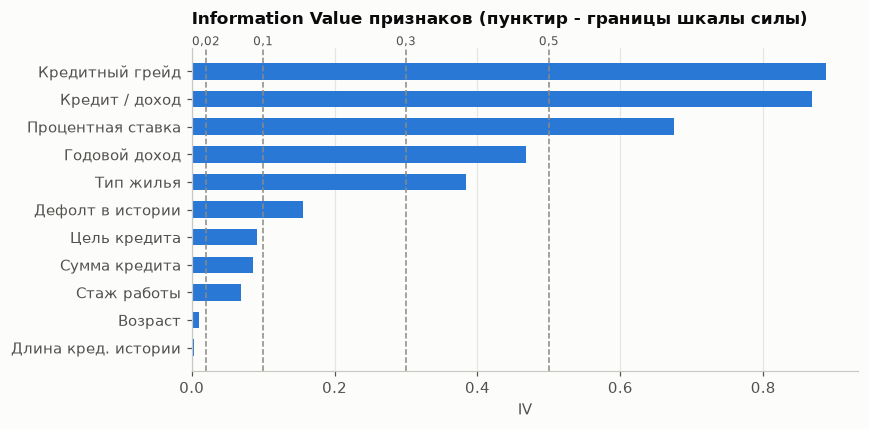

In [63]:
def woe_iv(x, target, bins=10):

    if x.name in NUM_COLS:
        x = pd.qcut(x, q=bins, labels=False, duplicates='drop').fillna(-1)
    t = pd.crosstab(x, target)
    good = (t[0] + 0.5) / t[0].sum()   
    bad = (t[1] + 0.5) / t[1].sum()
    woe = np.log(good / bad)
    return float(((good - bad) * woe).sum())

def iv_strength(v):
    return ('бесполезный' if v < 0.02 else 'слабый' if v < 0.1 else 'средний' if v < 0.3
            else 'сильный' if v < 0.5 else 'очень сильный')

iv = pd.Series({c: woe_iv(X_train_raw[c], y_train) for c in ALL_FEATURES}).sort_values(ascending=False)
iv_table = pd.DataFrame({'Признак': [RU[c] for c in iv.index], 'IV': iv.round(3).values,
                         'Сила': [iv_strength(v) for v in iv.values]}, index=iv.index)
display(iv_table)

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh([RU[c] for c in iv.index], iv.values, color=C['blue'], height=0.6)
for lvl, name in [(0.02, '0,02'), (0.1, '0,1'), (0.3, '0,3'), (0.5, '0,5')]:
    ax.axvline(lvl, color=C['muted'], linestyle='--', linewidth=1)
    ax.text(lvl, 1.01, name, transform=ax.get_xaxis_transform(), ha='center', color=C['ink2'], fontsize=8)
ax.invert_yaxis(); ax.grid(axis='y', visible=False)
ax.set_title('Information Value признаков (пунктир - границы шкалы силы)', pad=16); ax.set_xlabel('IV')
plt.tight_layout(); plt.show()

In [64]:
mi_frame = X_train_raw[ALL_FEATURES].copy()
mi_frame['person_emp_length'] = mi_frame['person_emp_length'].fillna(prep.emp_median_)
mi_frame['loan_int_rate'] = mi_frame['loan_int_rate'].fillna(mi_frame['loan_grade'].map(prep.rate_by_grade_))
for c in CAT_COLS:
    mi_frame[c] = mi_frame[c].astype('category').cat.codes
mi = pd.Series(mutual_info_classif(mi_frame, y_train, discrete_features=[c in CAT_COLS for c in ALL_FEATURES],
                                   random_state=RANDOM_STATE), index=ALL_FEATURES)

X_fit, X_val, y_fit, y_val = train_test_split(X_train_raw, y_train, test_size=0.2, stratify=y_train, random_state=RANDOM_STATE)
pre_model = make_pipeline(CreditPreprocessor(), HistGradientBoostingClassifier(random_state=RANDOM_STATE)).fit(X_fit, y_fit)
perm = permutation_importance(pre_model, X_val[ALL_FEATURES], y_val, scoring='roc_auc', n_repeats=10, random_state=RANDOM_STATE)
perm_imp = pd.Series(perm.importances_mean, index=ALL_FEATURES)

importance = pd.DataFrame({'Признак': [RU[c] for c in ALL_FEATURES], 'IV': iv[ALL_FEATURES].values,
                           'Mutual Info': mi.values, 'Permutation ΔAUC': perm_imp.values}, index=ALL_FEATURES)
importance['Ранг IV'] = importance['IV'].rank(ascending=False).astype(int)
importance['Ранг MI'] = importance['Mutual Info'].rank(ascending=False).astype(int)
importance['Ранг Perm'] = importance['Permutation ΔAUC'].rank(ascending=False).astype(int)
importance['Средний ранг'] = importance[['Ранг IV', 'Ранг MI', 'Ранг Perm']].mean(axis=1).round(1)
importance = importance.sort_values('Средний ранг')
importance.round(4)

,Признак,IV,Mutual Info,Permutation ΔAUC,Ранг IV,Ранг MI,Ранг Perm,Средний ранг
loan_percent_income,Кредит / доход,0.8685,0.0813,0.1050,2,2,1,1.7
person_income,Годовой доход,0.4681,0.1099,0.0902,4,1,2,2.3
loan_grade,Кредитный грейд,0.8882,0.0755,0.0652,1,4,4,3.0
loan_int_rate,Процентная ставка,0.6756,0.0771,0.0108,3,3,6,4.0
person_home_ownership,Тип жилья,0.3837,0.0313,0.0848,5,5,3,4.3
loan_intent,Цель кредита,0.0910,0.0077,0.0433,7,8,5,6.7
loan_amnt,Сумма кредита,0.0855,0.0147,0.0021,8,6,9,7.7
cb_person_default_on_file,Дефолт в истории,0.1552,0.0137,-0.0001,6,7,11,8.0
person_emp_length,Стаж работы,0.0697,0.0020,0.0065,9,9,7,8.3
person_age,Возраст,0.0108,0.0013,0.0044,10,10,8,9.3


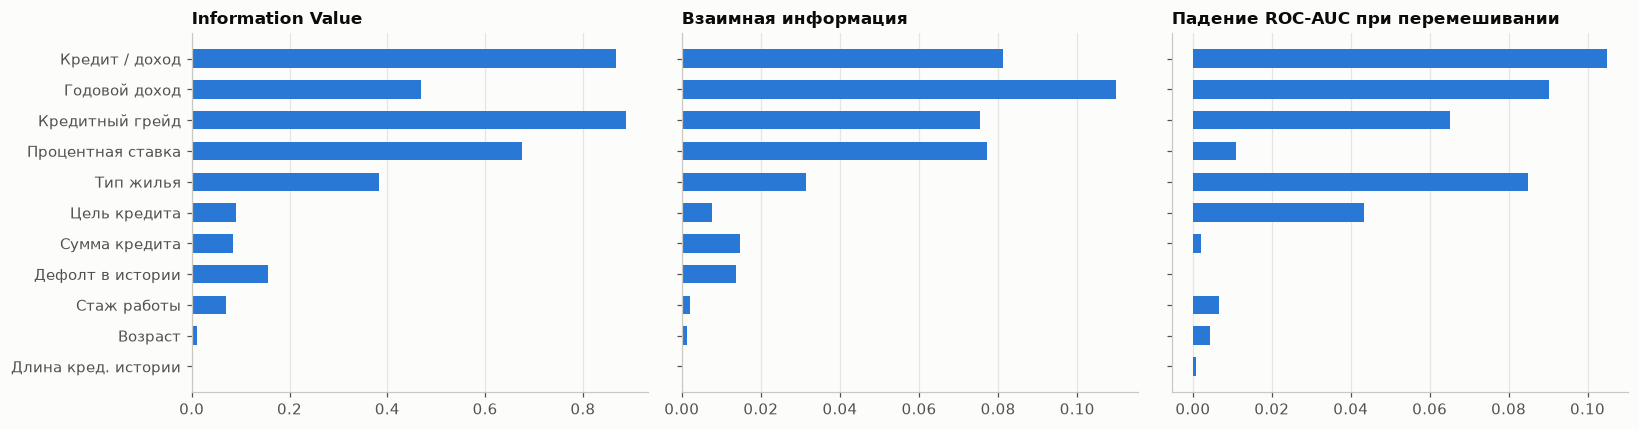

Пары признаков с |r| > 0,7:
  Возраст - Длина кред. истории: 0.86
  Процентная ставка - Кредитный грейд: 0.93


In [65]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
order = importance.index[::-1]
for ax, col, title in zip(axes, ['IV', 'Mutual Info', 'Permutation ΔAUC'],
                          ['Information Value', 'Взаимная информация', 'Падение ROC-AUC при перемешивании']):
    ax.barh([RU[c] for c in order], importance.loc[order, col], color=C['blue'], height=0.6)
    ax.set_title(title); ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

pairs = (corr.drop(index=TARGET, columns=TARGET).where(lambda m: np.triu(np.ones(m.shape, bool), 1))
         .stack().loc[lambda s: s.abs() > 0.7])
print('Пары признаков с |r| > 0,7:')
for (a, b), v in pairs.items():
    print(f'  {RU[a]} - {RU[b]}: {v:.2f}')

**Отбор признаков.** Все три метода сходятся: самые информативные - кредитный грейд, отношение кредита к доходу, доход, процентная ставка и тип жилья. Два признака не несут полезной информации:

* `person_age` (возраст) - IV < 0,02, почти нулевая взаимная информация и перестановочная важность;
* `cb_person_cred_hist_length` (длина кредитной истории) - то же самое, к тому же она на 0,86 коррелирует с возрастом.

Эти два признака исключаются. Пара «грейд - ставка» тоже сильно коррелирует, но оба признака сильные и несут немного разную информацию (ставка уточняет риск внутри грейда), поэтому для деревьев их оставляем. Проверим кросс-валидацией, что исключение признаков не ухудшает качество.

> Замечание: грейд и ставка назначаются кредитором по результатам первичной оценки риска, поэтому их высокий IV ожидаем. В реальной системе их можно использовать, только если они известны на момент принятия решения о выдаче.

In [66]:
DROPPED = ['person_age', 'cb_person_cred_hist_length']
SELECTED = [c for c in ALL_FEATURES if c not in DROPPED]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
check = {}
for name, feats in [('Все 11 признаков', ALL_FEATURES), (f'Отобранные {len(SELECTED)} признаков', SELECTED)]:
    pipe = make_pipeline(CreditPreprocessor(features=feats), HistGradientBoostingClassifier(random_state=RANDOM_STATE))
    s = cross_val_score(pipe, X_train_raw, y_train, cv=cv, scoring='roc_auc')
    check[name] = {'ROC-AUC (CV, среднее)': s.mean(), 'Ст. отклонение': s.std()}
display(pd.DataFrame(check).T.round(4))
print('Признаки, передаваемые в модель:', ', '.join(RU[c] for c in SELECTED))

,"ROC-AUC (CV, среднее)",Ст. отклонение
Все 11 признаков,0.9428,0.0029
Отобранные 9 признаков,0.9421,0.0033


Признаки, передаваемые в модель: Годовой доход, Стаж работы, Сумма кредита, Процентная ставка, Кредит / доход, Тип жилья, Цель кредита, Кредитный грейд, Дефолт в истории


## 5. Выбор модели

Сравниваем четыре модели на 5-кратной стратифицированной кросс-валидации по обучающей выборке:

| Модель | Тип | Зачем |
|---|---|---|
| Логистическая регрессия | линейная | базовая интерпретируемая модель, классика скоринговых карт |
| Случайный лес | ансамбль (бэггинг) | нелинейные зависимости, устойчивость к выбросам |
| Градиентный бустинг (HistGradientBoosting) | ансамбль (бустинг) | обычно лучший выбор для табличных данных |
| Soft Voting (лес + бустинг) | ансамбль ансамблей | усреднение вероятностей двух сильных моделей |

Веса классов **не балансируем** (`class_weight` не задаём): модель должна выдавать честную вероятность дефолта, потому что PD дальше напрямую используется в порогах 0,20 / 0,50 и в формуле Expected Value. Балансировка классов завысила бы PD.

In [67]:
def pipe(model, scale=False):
    steps = [CreditPreprocessor(features=SELECTED)] + ([StandardScaler()] if scale else []) + [model]
    return make_pipeline(*steps)

rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=RANDOM_STATE)
hgb = HistGradientBoostingClassifier(random_state=RANDOM_STATE)
models = {
    'Логистическая регрессия': pipe(LogisticRegression(max_iter=2000), scale=True),
    'Случайный лес': pipe(rf),
    'Градиентный бустинг': pipe(hgb),
    'Soft Voting (лес + бустинг)': pipe(VotingClassifier([('rf', clone(rf)), ('hgb', clone(hgb))], voting='soft')),
}

cv_results = {}
for name, m in models.items():
    s = cross_val_score(m, X_train_raw, y_train, cv=cv, scoring='roc_auc')
    cv_results[name] = {'ROC-AUC (CV)': s.mean(), 'Ст. отклонение': s.std(), 'Gini (CV)': 2 * s.mean() - 1}
cv_table = pd.DataFrame(cv_results).T.sort_values('ROC-AUC (CV)', ascending=False)
cv_table.round(4)

,ROC-AUC (CV),Ст. отклонение,Gini (CV)
Градиентный бустинг,0.9421,0.0033,0.8842
Soft Voting (лес + бустинг),0.9401,0.0032,0.8803
Случайный лес,0.9310,0.0035,0.8619
Логистическая регрессия,0.8636,0.0036,0.7272


Подберём гиперпараметры лучшей модели - градиентного бустинга - случайным поиском по сетке с той же кросс-валидацией.

Лучшие параметры: {'min_samples_leaf': 100, 'max_leaf_nodes': 15, 'max_iter': 600, 'learning_rate': 0.1, 'l2_regularization': 1.0}
ROC-AUC (CV) после подбора: 0.9434


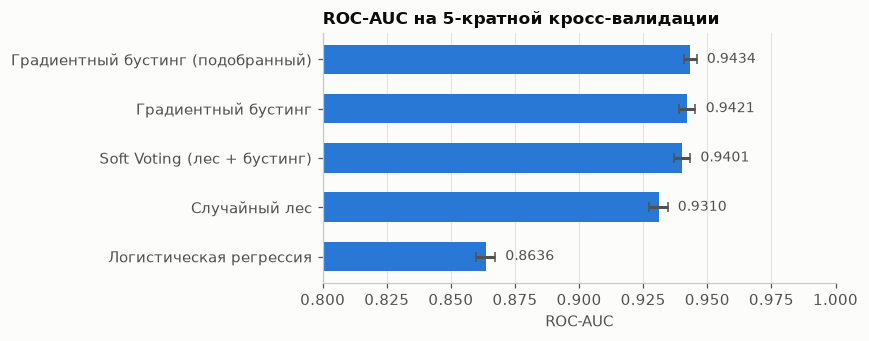

,ROC-AUC (CV),Ст. отклонение,Gini (CV)
Градиентный бустинг (подобранный),0.9434,0.0024,0.8868
Градиентный бустинг,0.9421,0.0033,0.8842
Soft Voting (лес + бустинг),0.9401,0.0032,0.8803
Случайный лес,0.9310,0.0035,0.8619
Логистическая регрессия,0.8636,0.0036,0.7272


In [68]:
param_dist = {
    'histgradientboostingclassifier__learning_rate': [0.03, 0.05, 0.1],
    'histgradientboostingclassifier__max_leaf_nodes': [15, 31, 63],
    'histgradientboostingclassifier__min_samples_leaf': [20, 50, 100],
    'histgradientboostingclassifier__l2_regularization': [0.0, 1.0, 5.0],
    'histgradientboostingclassifier__max_iter': [300, 600],
}
search = RandomizedSearchCV(pipe(HistGradientBoostingClassifier(random_state=RANDOM_STATE)), param_dist,
                            n_iter=12, scoring='roc_auc', cv=cv, random_state=RANDOM_STATE, n_jobs=-1)
search.fit(X_train_raw, y_train)

best_params = {k.split('__')[1]: v for k, v in search.best_params_.items()}
print('Лучшие параметры:', best_params)
print(f'ROC-AUC (CV) после подбора: {search.best_score_:.4f}')
cv_table.loc['Градиентный бустинг (подобранный)'] = {
    'ROC-AUC (CV)': search.best_score_,
    'Ст. отклонение': search.cv_results_['std_test_score'][search.best_index_],
    'Gini (CV)': 2 * search.best_score_ - 1}
cv_table = cv_table.sort_values('ROC-AUC (CV)', ascending=False)

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(cv_table.index, cv_table['ROC-AUC (CV)'], xerr=cv_table['Ст. отклонение'], color=C['blue'], height=0.6,
        error_kw={'ecolor': C['ink2'], 'capsize': 3})
for i, (v, sd) in enumerate(zip(cv_table['ROC-AUC (CV)'], cv_table['Ст. отклонение'])):
    ax.text(v + sd + 0.004, i, f'{v:.4f}', va='center', fontsize=9, color=C['ink2'])
ax.set_xlim(0.8, 1.0); ax.invert_yaxis(); ax.grid(axis='y', visible=False)
ax.set_title('ROC-AUC на 5-кратной кросс-валидации'); ax.set_xlabel('ROC-AUC')
plt.tight_layout(); plt.show()
cv_table.round(4)

In [69]:
models['Градиентный бустинг (подобранный)'] = search.best_estimator_
best_name = cv_table.index[0]
final_model = clone(models[best_name]).fit(X_train_raw, y_train)
print('Выбрана модель:', best_name)

test_pd = {}
for name, m in models.items():
    fitted = final_model if name == best_name else clone(m).fit(X_train_raw, y_train)
    test_pd[name] = fitted.predict_proba(X_test_raw)[:, 1]

pd_train = final_model.predict_proba(X_train_raw)[:, 1]
pd_test = test_pd[best_name]

Выбрана модель: Градиентный бустинг (подобранный)


## 6. Метрики качества модели

Основная метрика - **ROC-AUC**: вероятность того, что случайно взятый дефолтный заёмщик получит более высокий PD, чем случайно взятый надёжный. Не зависит от порога и от дисбаланса классов.

Дополнительно:
* **Gini** $= 2\cdot ROC\text{-}AUC - 1$ - стандарт банковской отрасли;
* **KS** (статистика Колмогорова - Смирнова) - максимальное расстояние между распределениями PD у надёжных и дефолтных;
* **PR-AUC** - площадь под кривой «точность - полнота», чувствительна к редкому классу;
* **Brier score** и **LogLoss** - качество самих вероятностей (калибровка), важно для расчёта Expected Value;
* Accuracy, Precision, Recall, F1 - при пороге 0,5.

In [70]:
def ks_stat(y_true, p):
    fpr, tpr, _ = roc_curve(y_true, p)
    return np.max(tpr - fpr)

def metrics(y_true, p, thr=0.5):
    pred = (p >= thr).astype(int)
    auc = roc_auc_score(y_true, p)
    return {'ROC-AUC': auc, 'Gini': 2 * auc - 1, 'KS': ks_stat(y_true, p),
            'PR-AUC': average_precision_score(y_true, p), 'Brier': brier_score_loss(y_true, p),
            'LogLoss': log_loss(y_true, p), 'Accuracy': accuracy_score(y_true, pred),
            'Precision': precision_score(y_true, pred), 'Recall': recall_score(y_true, pred),
            'F1': f1_score(y_true, pred)}

final_metrics = pd.DataFrame({'Обучающая': metrics(y_train, pd_train), 'Тестовая': metrics(y_test, pd_test)})
display(Markdown(f'**{best_name}** - метрики на обучающей и тестовой выборках'))
display(final_metrics.round(4))

comparison = pd.DataFrame({name: metrics(y_test, p) for name, p in test_pd.items()}).T.sort_values('ROC-AUC', ascending=False)
display(Markdown('**Сравнение всех моделей на тестовой выборке**'))
display(comparison[['ROC-AUC', 'Gini', 'KS', 'PR-AUC', 'Brier', 'F1']].round(4))

**Градиентный бустинг (подобранный)** - метрики на обучающей и тестовой выборках

,Обучающая,Тестовая
ROC-AUC,0.9636,0.9461
Gini,0.9272,0.8922
KS,0.7880,0.7565
PR-AUC,0.9248,0.9020
Brier,0.0488,0.0530
LogLoss,0.1732,0.1910
Accuracy,0.9373,0.9352
Precision,0.9800,0.9677
Recall,0.7284,0.7280
F1,0.8357,0.8309


**Сравнение всех моделей на тестовой выборке**

,ROC-AUC,Gini,KS,PR-AUC,Brier,F1
Градиентный бустинг (подобранный),0.9461,0.8922,0.7565,0.9020,0.0530,0.8309
Градиентный бустинг,0.9459,0.8918,0.7535,0.9018,0.0527,0.8317
Soft Voting (лес + бустинг),0.9425,0.8851,0.7479,0.8980,0.0537,0.8326
Случайный лес,0.9330,0.8661,0.7298,0.8868,0.0566,0.8306
Логистическая регрессия,0.8633,0.7266,0.5775,0.6945,0.1089,0.5939


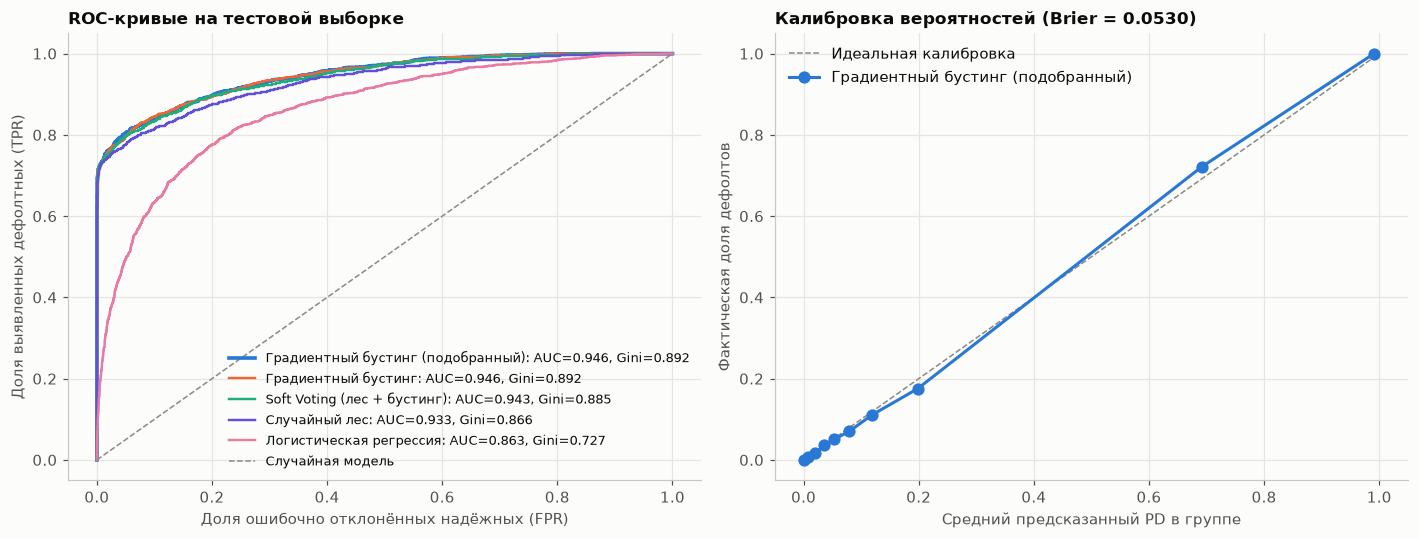

Средний предсказанный PD на тесте: 0.2197; фактическая доля дефолтов: 0.2187


In [71]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ax = axes[0]
colors = [C['blue'], C['orange'], C['aqua'], C['violet'], C['magenta']]
for (name, p), col in zip(sorted(test_pd.items(), key=lambda kv: -roc_auc_score(y_test, kv[1])), colors):
    fpr, tpr, _ = roc_curve(y_test, p)
    auc = roc_auc_score(y_test, p)
    ax.plot(fpr, tpr, color=col, linewidth=2.4 if name == best_name else 1.6,
            label=f'{name}: AUC={auc:.3f}, Gini={2*auc-1:.3f}')
ax.plot([0, 1], [0, 1], color=C['muted'], linestyle='--', linewidth=1, label='Случайная модель')
ax.set_xlabel('Доля ошибочно отклонённых надёжных (FPR)'); ax.set_ylabel('Доля выявленных дефолтных (TPR)')
ax.set_title('ROC-кривые на тестовой выборке'); ax.legend(loc='lower right', fontsize=8.5)

ax = axes[1]
frac_pos, mean_pred = calibration_curve(y_test, pd_test, n_bins=10, strategy='quantile')
ax.plot([0, 1], [0, 1], color=C['muted'], linestyle='--', linewidth=1, label='Идеальная калибровка')
ax.plot(mean_pred, frac_pos, marker='o', markersize=7, color=C['blue'], label=best_name)
ax.set_xlabel('Средний предсказанный PD в группе'); ax.set_ylabel('Фактическая доля дефолтов')
ax.set_title(f'Калибровка вероятностей (Brier = {brier_score_loss(y_test, pd_test):.4f})'); ax.legend(loc='upper left')
plt.tight_layout(); plt.show()
print(f'Средний предсказанный PD на тесте: {pd_test.mean():.4f}; фактическая доля дефолтов: {y_test.mean():.4f}')

**Матрица ошибок при пороге 0,5**

,Прогноз: надёжный,Прогноз: дефолт
Факт: надёжный,6288,43
Факт: дефолт,482,1290


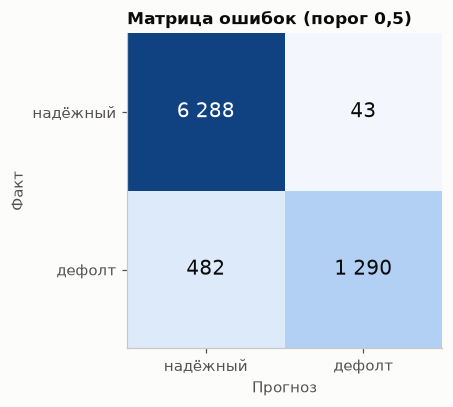

              precision    recall  f1-score   support

    Надёжный     0.9288    0.9932    0.9599      6331
      Дефолт     0.9677    0.7280    0.8309      1772

    accuracy                         0.9352      8103
   macro avg     0.9483    0.8606    0.8954      8103
weighted avg     0.9373    0.9352    0.9317      8103



In [72]:
cm = confusion_matrix(y_test, (pd_test >= 0.5).astype(int))
cm_df = pd.DataFrame(cm, index=['Факт: надёжный', 'Факт: дефолт'], columns=['Прогноз: надёжный', 'Прогноз: дефолт'])
display(Markdown('**Матрица ошибок при пороге 0,5**'))
display(cm_df)

fig, ax = plt.subplots(figsize=(4.6, 3.8))
ax.imshow(cm, cmap=SEQUENTIAL); ax.grid(False)
for i in range(2):
    for j in range(2):
        ax.text(j, i, money(cm[i, j]), ha='center', va='center', fontsize=13,
                color='white' if cm[i, j] > cm.max() / 2 else C['ink'])
ax.set_xticks([0, 1]); ax.set_xticklabels(['надёжный', 'дефолт']); ax.set_xlabel('Прогноз')
ax.set_yticks([0, 1]); ax.set_yticklabels(['надёжный', 'дефолт']); ax.set_ylabel('Факт')
ax.set_title('Матрица ошибок (порог 0,5)')
plt.tight_layout(); plt.show()
print(classification_report(y_test, (pd_test >= 0.5).astype(int), target_names=['Надёжный', 'Дефолт'], digits=4))

## 7. Gini, доля выявленных дефолтных и доля ошибочно отклонённых надёжных заёмщиков

* $Gini = 2\cdot ROC\text{-}AUC - 1$
* **Доля выявленных дефолтных заёмщиков** (TPR, полнота) $=\dfrac{TP}{TP+FN}$ - какая часть реальных дефолтов получила PD не ниже порога.
* **Доля ошибочно отклонённых надёжных заёмщиков** (FPR) $=\dfrac{FP}{FP+TN}$ - какая часть добросовестных заёмщиков получила отказ.

Считаем при двух порогах из пункта 9: **0,50** (автоматический отказ) и **0,20** (всё, что не одобрено автоматически, - отказ + доп. проверка).

In [73]:
auc_test = roc_auc_score(y_test, pd_test)
gini_test = 2 * auc_test - 1
print(f'ROC-AUC = {auc_test:.4f}')
print(f'Gini = 2 × {auc_test:.4f} − 1 = {gini_test:.4f}\n')

def capture_rates(y_true, p, thr):
    flag = p >= thr
    y_true = np.asarray(y_true)
    tp = int((flag & (y_true == 1)).sum()); fn = int((~flag & (y_true == 1)).sum())
    fp = int((flag & (y_true == 0)).sum()); tn = int((~flag & (y_true == 0)).sum())
    return {'Порог PD': thr, 'Выявлено дефолтных (TP)': tp, 'Пропущено дефолтных (FN)': fn,
            'Доля выявленных дефолтных (TPR)': tp / (tp + fn),
            'Ошибочно отклонено надёжных (FP)': fp,
            'Доля ошибочно отклонённых надёжных (FPR)': fp / (fp + tn)}

rates = pd.DataFrame([capture_rates(y_test, pd_test, t) for t in [0.2, 0.3, 0.5]]).set_index('Порог PD')
rates.round(4)

ROC-AUC = 0.9461
Gini = 2 × 0.9461 − 1 = 0.8922



,Выявлено дефолтных (TP),Пропущено дефолтных (FN),Доля выявленных дефолтных (TPR),Ошибочно отклонено надёжных (FP),Доля ошибочно отклонённых надёжных (FPR)
Порог PD,,,,,
0.2,1462,310,0.8251,502,0.0793
0.3,1374,398,0.7754,189,0.0299
0.5,1290,482,0.7280,43,0.0068


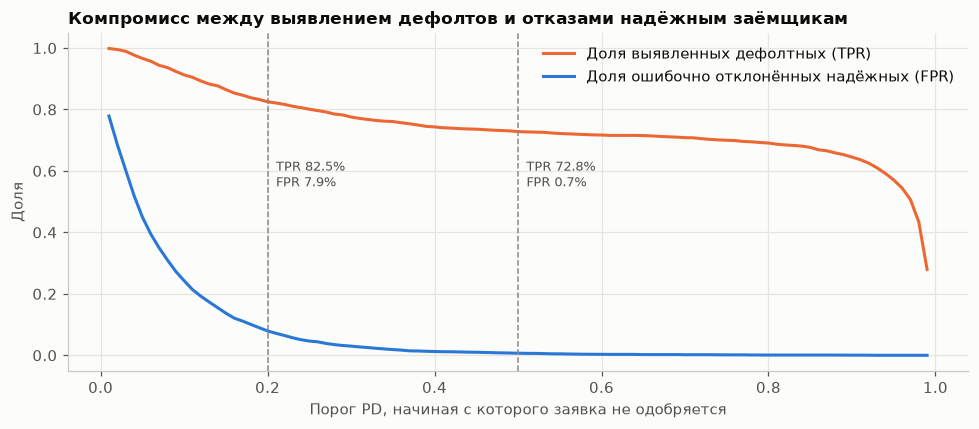

In [74]:
thr_grid = np.linspace(0.01, 0.99, 99)
curve = pd.DataFrame([capture_rates(y_test, pd_test, t) for t in thr_grid]).set_index('Порог PD')

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(curve.index, curve['Доля выявленных дефолтных (TPR)'], color=C['orange'], label='Доля выявленных дефолтных (TPR)')
ax.plot(curve.index, curve['Доля ошибочно отклонённых надёжных (FPR)'], color=C['blue'], label='Доля ошибочно отклонённых надёжных (FPR)')
for t in [0.2, 0.5]:
    ax.axvline(t, color=C['muted'], linestyle='--', linewidth=1)
    r = capture_rates(y_test, pd_test, t)
    ax.annotate(f"TPR {r['Доля выявленных дефолтных (TPR)']:.1%}\nFPR {r['Доля ошибочно отклонённых надёжных (FPR)']:.1%}",
                xy=(t, 0.55), xytext=(t + 0.01, 0.55), fontsize=8.5, color=C['ink2'])
ax.set_xlabel('Порог PD, начиная с которого заявка не одобряется'); ax.set_ylabel('Доля')
ax.set_title('Компромисс между выявлением дефолтов и отказами надёжным заёмщикам'); ax.legend(loc='upper right')
plt.tight_layout(); plt.show()

## 8. Пороги решения

| PD | Решение |
|---|---|
| < 0,20 | **Одобрить** автоматически |
| 0,20 – 0,50 | **Направить на дополнительную проверку** (андеррайтер, документы, залог) |
| > 0,50 | **Отклонить** |

In [75]:
ZONES = ['Одобрить', 'Доп. проверка', 'Отклонить']
def decision_zone(p, low=0.2, high=0.5):
    return pd.Categorical(np.select([p < low, p <= high], ZONES[:2], default=ZONES[2]), categories=ZONES, ordered=True)

res = X_test_raw.copy()
res['y'] = y_test.values
res['PD'] = pd_test
res['Зона'] = decision_zone(pd_test)

zone_table = res.groupby('Зона', observed=False).agg(
    Заявок=('y', 'size'), Средний_PD=('PD', 'mean'), Фактическая_доля_дефолтов=('y', 'mean'),
    Дефолтных=('y', 'sum'), Средняя_сумма=('loan_amnt', 'mean'))
zone_table['Надёжных'] = zone_table['Заявок'] - zone_table['Дефолтных']
zone_table['Доля заявок'] = zone_table['Заявок'] / zone_table['Заявок'].sum()
zone_table['Доля от всех дефолтов'] = zone_table['Дефолтных'] / zone_table['Дефолтных'].sum()
zone_table = zone_table[['Заявок', 'Доля заявок', 'Средний_PD', 'Фактическая_доля_дефолтов',
                         'Дефолтных', 'Надёжных', 'Доля от всех дефолтов', 'Средняя_сумма']]
zone_table.round(3)

,Заявок,Доля заявок,Средний_PD,Фактическая_доля_дефолтов,Дефолтных,Надёжных,Доля от всех дефолтов,Средняя_сумма
Зона,,,,,,,,
Одобрить,6139,0.758,0.055,0.050,310,5829,0.175,9158.100
Доп. проверка,631,0.078,0.290,0.273,172,459,0.097,9510.737
Отклонить,1333,0.165,0.946,0.968,1290,43,0.728,11648.050


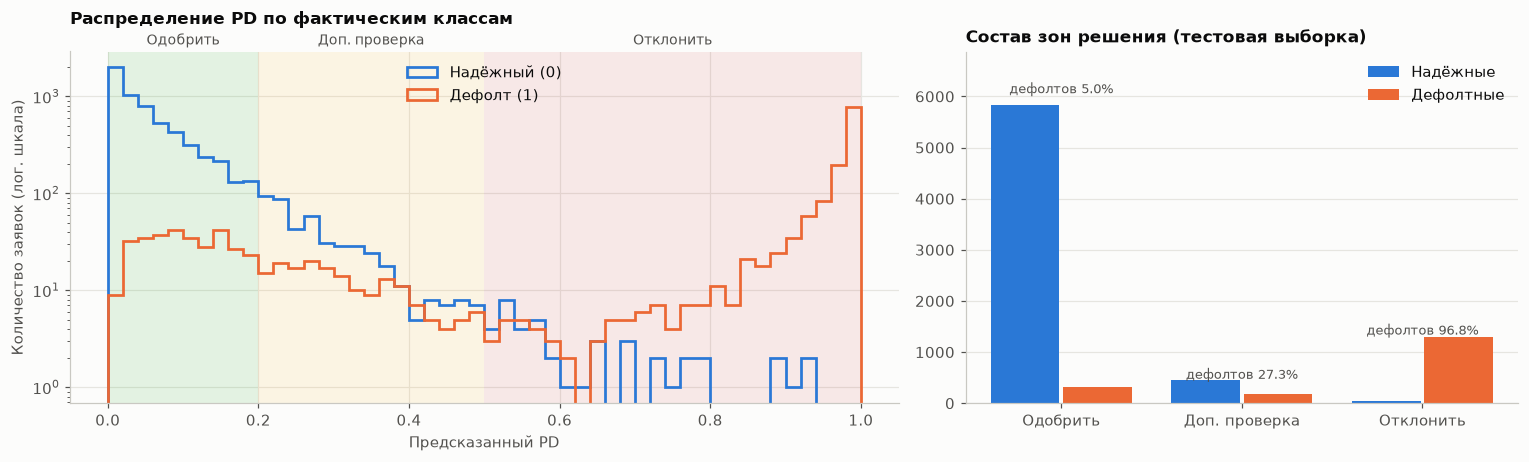

In [76]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3), gridspec_kw={'width_ratios': [3, 2]})
ax = axes[0]
bins = np.linspace(0, 1, 51)
for (lo, hi), z in zip([(0, 0.2), (0.2, 0.5), (0.5, 1)], ZONES):
    ax.axvspan(lo, hi, color=STATUS[z], alpha=0.10, linewidth=0)
    ax.text((lo + hi) / 2, 1.02, z, transform=ax.get_xaxis_transform(), ha='center', fontsize=9, color=C['ink2'])
for cls in [0, 1]:
    ax.hist(res.loc[res['y'] == cls, 'PD'], bins=bins, histtype='step', linewidth=1.8,
            color=CLASS_COLORS[cls], label=CLASS_NAMES[cls])
ax.set_yscale('log'); ax.set_xlabel('Предсказанный PD'); ax.set_ylabel('Количество заявок (лог. шкала)')
ax.set_title('Распределение PD по фактическим классам', pad=18); ax.legend(loc='upper center')

ax = axes[1]
x = np.arange(len(ZONES))
ax.bar(x - 0.2, zone_table['Надёжных'], width=0.38, color=C['blue'], label='Надёжные')
ax.bar(x + 0.2, zone_table['Дефолтных'], width=0.38, color=C['orange'], label='Дефолтные')
for i, z in enumerate(ZONES):
    ax.text(i, max(zone_table.loc[z, 'Надёжных'], zone_table.loc[z, 'Дефолтных']) * 1.04,
            f"дефолтов {zone_table.loc[z, 'Фактическая_доля_дефолтов']:.1%}", ha='center', fontsize=8.5, color=C['ink2'])
ax.set_xticks(x); ax.set_xticklabels(ZONES); ax.grid(axis='x', visible=False)
ax.set_ylim(0, zone_table[['Надёжных', 'Дефолтных']].values.max() * 1.18)
ax.set_title('Состав зон решения (тестовая выборка)'); ax.legend()
plt.tight_layout(); plt.show()

## 9. Экономический эффект

Ожидаемая ценность кредита для банка:
$$EV = (1 - PD)\cdot R - PD\cdot L$$

**Допущения расчёта** (для каждого кредита отдельно):
* $R$ - процентный доход банка за год: $R = \text{сумма кредита}\times\text{ставка}$ (пропущенная ставка заполнена медианой грейда);
* $L$ - потери при дефолте: $L = \text{сумма кредита}\times LGD$, где **LGD = 60 %** - базовое допущение для необеспеченного потребкредита (часть долга банк возвращает через взыскание); ниже есть анализ чувствительности к LGD;
* срок - 1 год, стоимость фондирования и операционные расходы не учитываются; суммы - в условных единицах датасета.

Из формулы следует **точка безубыточности** по PD: $EV > 0 \iff PD < \dfrac{R}{R+L} = \dfrac{r}{r+LGD}$. При средней ставке ≈ 11 % и LGD = 60 % это PD ≈ 0,15–0,16 - то есть порог одобрения 0,20 близок к экономически обоснованному.

Сравниваем сценарии оценки заёмщиков на тестовой выборке. По каждому сценарию считаем **ожидаемую прибыль** (Σ EV по одобренным, по PD модели) и **фактическую прибыль** (по реальным исходам: +R, если кредит вернули, −L, если дефолт).

In [77]:
LGD = 0.60
rate_filled = res['loan_int_rate'].fillna(res['loan_grade'].map(prep.rate_by_grade_)) / 100

def economics(frame, lgd):
    f = frame.copy()
    f['R'] = f['loan_amnt'] * rate_filled
    f['L'] = f['loan_amnt'] * lgd
    f['EV'] = (1 - f['PD']) * f['R'] - f['PD'] * f['L']
    f['Факт_прибыль'] = np.where(f['y'] == 1, -f['L'], f['R'])
    f['PD_безубыточности'] = f['R'] / (f['R'] + f['L'])
    return f

res = economics(res, LGD)
display(res[['loan_amnt', 'loan_int_rate', 'PD', 'Зона', 'R', 'L', 'EV', 'y', 'Факт_прибыль']].head(8).round(3))
print(f"Средняя точка безубыточности PD = {res['PD_безубыточности'].mean():.3f} "
      f"(от {res['PD_безубыточности'].min():.3f} до {res['PD_безубыточности'].max():.3f})")
print(f"Заявок с положительным EV: {(res['EV'] > 0).mean():.1%}")

,loan_amnt,loan_int_rate,PD,Зона,R,L,EV,y,Факт_прибыль
29984,7000,7.90,0.051,Одобрить,553.00,4200.0,311.156,0,553.00
22466,8400,NaN,0.773,Отклонить,1286.04,5040.0,-3605.020,1,-5040.00
3190,12000,5.99,0.114,Одобрить,718.80,7200.0,-184.442,1,-7200.00
7489,6800,11.49,0.005,Одобрить,781.32,4080.0,758.244,0,781.32
24154,4200,9.91,0.058,Одобрить,416.22,2520.0,245.313,1,-2520.00
25944,15000,5.99,0.018,Одобрить,898.50,9000.0,719.310,0,898.50
26413,2500,11.36,0.000,Одобрить,284.00,1500.0,283.425,0,284.00
5209,9000,5.79,0.012,Одобрить,521.10,5400.0,449.609,0,521.10


Средняя точка безубыточности PD = 0.153 (от 0.083 до 0.269)
Заявок с положительным EV: 71.9%


In [78]:
def scenarios(f):
    z = f['Зона']
    return {
        '1. Без модели (одобрить всех)': pd.Series(True, index=f.index),
        '2. Консервативный: только PD < 0,20': z == 'Одобрить',
        '3. Либеральный: PD ≤ 0,50 (проверка → одобрение)': z != 'Отклонить',
        '4. Три зоны: в зоне проверки - по знаку EV': (z == 'Одобрить') | ((z == 'Доп. проверка') & (f['EV'] > 0)),
        '5. EV-оптимальный: одобрять при EV > 0': f['EV'] > 0,
        '6. Идеальная модель (знает исход, ориентир)': f['y'] == 0,
    }

def evaluate(f):
    rows = {}
    base_fact = f['Факт_прибыль'].sum()
    for name, mask in scenarios(f).items():
        a = f[mask]
        rows[name] = {
            'Одобрено': len(a), 'Уровень одобрения': len(a) / len(f),
            'Дефолтов среди одобренных': int(a['y'].sum()), 'Доля дефолтов в портфеле': a['y'].mean(),
            'Отказано надёжным': int(((~mask) & (f['y'] == 0)).sum()),
            'Ожидаемая прибыль (Σ EV)': np.nan if name.startswith('6') else a['EV'].sum(),
            'Фактическая прибыль': a['Факт_прибыль'].sum(),
            'Прирост к «без модели»': a['Факт_прибыль'].sum() - base_fact,
            'Прибыль на 1 одобренный кредит': a['Факт_прибыль'].mean(),
        }
    return pd.DataFrame(rows).T

scen = evaluate(res)
show = scen.copy()
for c in ['Ожидаемая прибыль (Σ EV)', 'Фактическая прибыль', 'Прирост к «без модели»', 'Прибыль на 1 одобренный кредит']:
    show[c] = show[c].map(lambda v: '-' if pd.isna(v) else money(v))
for c in ['Уровень одобрения', 'Доля дефолтов в портфеле']:
    show[c] = show[c].map(lambda v: f'{v:.1%}')
for c in ['Одобрено', 'Дефолтов среди одобренных', 'Отказано надёжным']:
    show[c] = show[c].astype(int)
display(Markdown(f'**Сценарии на тестовой выборке ({len(res):,} заявок), LGD = {LGD:.0%}**'.replace(',', ' ')))
show

**Сценарии на тестовой выборке (8 103 заявок)  LGD = 60%**

,Одобрено,Уровень одобрения,Дефолтов среди одобренных,Доля дефолтов в портфеле,Отказано надёжным,Ожидаемая прибыль (Σ EV),Фактическая прибыль,Прирост к «без модели»,Прибыль на 1 одобренный кредит
1. Без модели (одобрить всех),8103,100.0%,1772,21.9%,0,-5 543 436,-5 417 430,0,-669
"2. Консервативный: только PD < 0,20",6139,75.8%,310,5.0%,502,3 680 584,3 929 501,9 346 931,640
"3. Либеральный: PD ≤ 0,50 (проверка → одобрение)",6770,83.5%,482,7.1%,43,3 207 968,3 563 064,8 980 494,526
4. Три зоны: в зоне проверки - по знаку EV,6155,76.0%,311,5.1%,487,3 681 383,3 947 386,9 364 816,641
5. EV-оптимальный: одобрять при EV > 0,5827,71.9%,263,4.5%,767,3 725 394,3 966 343,9 383 773,681
"6. Идеальная модель (знает исход, ориентир)",6331,78.1%,0,0.0%,0,-,6 231 420,11 648 850,984


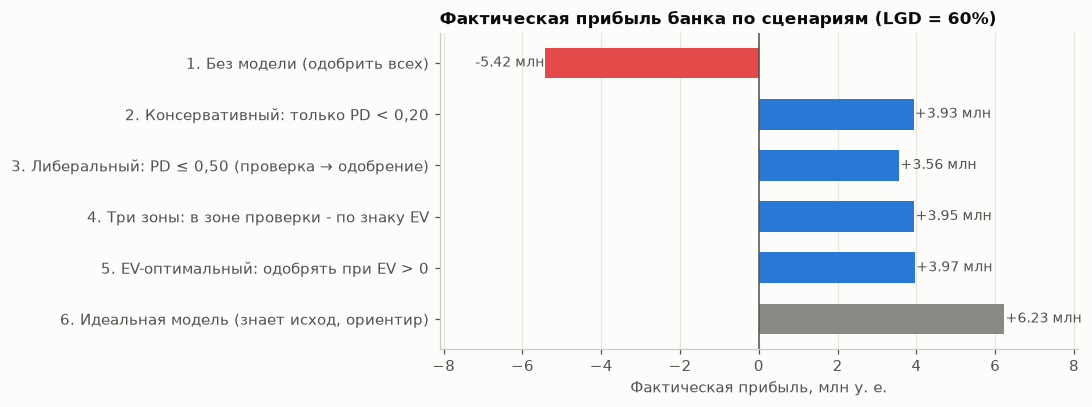

In [79]:
fig, ax = plt.subplots(figsize=(10, 3.8))
vals = scen['Фактическая прибыль'] / 1e6
names = list(scen.index)
colors = [C['red'] if v < 0 else (C['muted'] if n.startswith('6') else C['blue']) for n, v in zip(names, vals)]
ax.barh(names, vals, color=colors, height=0.6)
for i, v in enumerate(vals):
    ax.text(v + (0.03 if v >= 0 else -0.03), i, f'{v:+.2f} млн', va='center', ha='left' if v >= 0 else 'right',
            fontsize=9, color=C['ink2'])
ax.axvline(0, color=C['ink2'], linewidth=1)
lim = max(abs(vals.min()), abs(vals.max())) * 1.3
ax.set_xlim(-lim, lim)
ax.invert_yaxis(); ax.grid(axis='y', visible=False)
ax.set_xlabel('Фактическая прибыль, млн у. е.'); ax.set_title(f'Фактическая прибыль банка по сценариям (LGD = {LGD:.0%})')
plt.tight_layout(); plt.show()

### 9.1 Чувствительность к уровню потерь LGD и выбор порога одобрения

**Фактическая прибыль (у. е.) по сценариям при разных LGD**

,LGD 30%,LGD 45%,LGD 60%,LGD 75%,LGD 100%
1. Без модели (одобрить всех),406 995,-2 505 218,-5 417 430,-8 329 643,-13 183 330
"2. Консервативный: только PD < 0,20",4 739 343,4 334 422,3 929 501,3 524 579,2 849 711
"3. Либеральный: PD ≤ 0,50 (проверка → одобрение)",4 861 906,4 212 485,3 563 064,2 913 642,1 831 274
4. Три зоны: в зоне проверки - по знаку EV,4 971 059,4 428 101,3 947 386,3 524 579,2 849 711
5. EV-оптимальный: одобрять при EV > 0,4 969 873,4 411 048,3 966 343,3 604 593,3 152 410
"6. Идеальная модель (знает исход, ориентир)",6 231 420,6 231 420,6 231 420,6 231 420,6 231 420


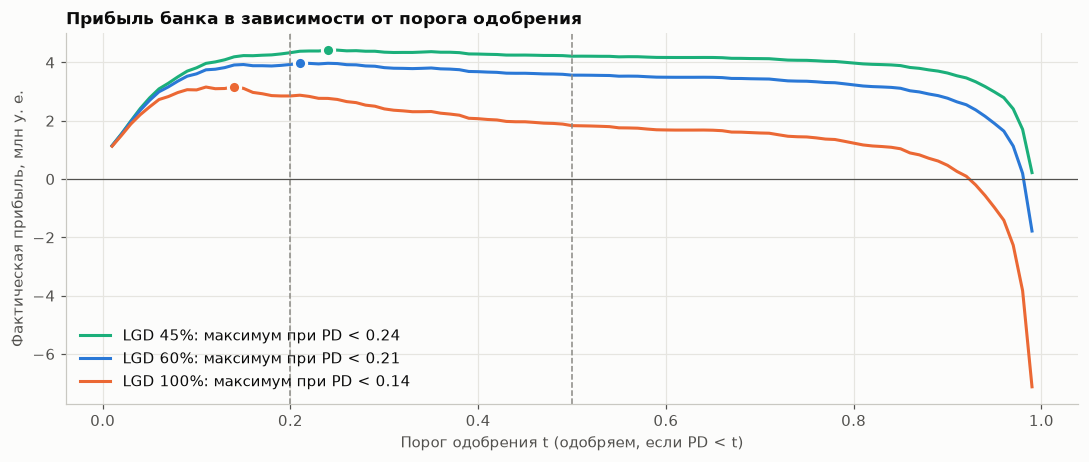

LGD 45%: оптимальный единый порог PD < 0.24, прибыль 4.422 млн у. е.
LGD 60%: оптимальный единый порог PD < 0.21, прибыль 3.972 млн у. е.
LGD 100%: оптимальный единый порог PD < 0.14, прибыль 3.163 млн у. е.


In [80]:
LGD_GRID = [0.30, 0.45, 0.60, 0.75, 1.00]
sens = pd.DataFrame({f'LGD {l:.0%}': evaluate(economics(res, l))['Фактическая прибыль'] for l in LGD_GRID})
display(Markdown('**Фактическая прибыль (у. е.) по сценариям при разных LGD**'))
display(sens.apply(lambda col: col.map(money)))

fig, ax = plt.subplots(figsize=(10, 4.3))
best_thr = {}
for l, col in zip([0.45, 0.60, 1.00], [C['aqua'], C['blue'], C['orange']]):
    f = economics(res, l)
    profit = np.array([f.loc[f['PD'] < t, 'Факт_прибыль'].sum() for t in thr_grid]) / 1e6
    i = profit.argmax(); best_thr[l] = (thr_grid[i], profit[i])
    ax.plot(thr_grid, profit, color=col, label=f'LGD {l:.0%}: максимум при PD < {thr_grid[i]:.2f}')
    ax.plot(thr_grid[i], profit[i], 'o', color=col, markersize=8, markeredgecolor=C['surface'], markeredgewidth=2)
for t in [0.2, 0.5]:
    ax.axvline(t, color=C['muted'], linestyle='--', linewidth=1)
ax.axhline(0, color=C['ink2'], linewidth=0.8)
ax.set_xlabel('Порог одобрения t (одобряем, если PD < t)'); ax.set_ylabel('Фактическая прибыль, млн у. е.')
ax.set_title('Прибыль банка в зависимости от порога одобрения'); ax.legend(loc='lower left')
plt.tight_layout(); plt.show()
for l, (t, p) in best_thr.items():
    print(f'LGD {l:.0%}: оптимальный единый порог PD < {t:.2f}, прибыль {p:.3f} млн у. е.')

## 10. Выводы
### 10.1 Профиль рискованного заёмщика
Сравним заёмщиков из зоны «Отклонить» (PD > 0,5) с заёмщиками из зоны «Одобрить» (PD < 0,2) на тестовой выборке.

In [81]:
def profile(f):
    return pd.Series({
        'Заявок': len(f),
        'Фактическая доля дефолтов': f['y'].mean(),
        'Медианный годовой доход': f['person_income'].median(),
        'Средняя сумма кредита': f['loan_amnt'].mean(),
        'Среднее отношение кредит / доход': f['loan_percent_income'].mean(),
        'Средняя ставка, %': f['loan_int_rate'].mean(),
        'Средний стаж, лет': f['person_emp_length'].mean(),
        'Доля арендующих жильё (RENT)': (f['person_home_ownership'] == 'RENT').mean(),
        'Доля с ипотекой (MORTGAGE)': (f['person_home_ownership'] == 'MORTGAGE').mean(),
        'Доля с грейдом D–G': f['loan_grade'].isin(list('DEFG')).mean(),
        'Доля с дефолтом в истории': (f['cb_person_default_on_file'] == 'Y').mean(),
        'Самая частая цель кредита': f['loan_intent'].mode()[0],
    })

prof = pd.DataFrame({z: profile(res[res['Зона'] == z]) for z in ZONES})
prof['Вся тестовая выборка'] = profile(res)
def fmt_row(label, v):
    if isinstance(v, str):
        return v
    if 'доля' in label.lower():
        return f'{v:.1%}'
    if label == 'Заявок':
        return money(v)
    return f'{v:,.2f}'.replace(',', ' ')

prof.apply(lambda col: pd.Series([fmt_row(i, v) for i, v in col.items()], index=col.index))

,Одобрить,Доп. проверка,Отклонить,Вся тестовая выборка
Заявок,6 139,631,1 333,8 103
Фактическая доля дефолтов,5.0%,27.3%,96.8%,21.9%
Медианный годовой доход,60 000.00,44 400.00,38 000.00,55 000.00
Средняя сумма кредита,9 158.10,9 510.74,11 648.05,9 595.17
Среднее отношение кредит / доход,0.14,0.19,0.28,0.17
"Средняя ставка, %",10.18,13.28,13.48,10.98
"Средний стаж, лет",4.92,5.20,3.77,4.75
Доля арендующих жильё (RENT),44.3%,48.0%,81.2%,50.7%
Доля с ипотекой (MORTGAGE),45.4%,51.0%,15.2%,40.9%
Доля с грейдом D–G,5.3%,33.0%,52.2%,15.1%


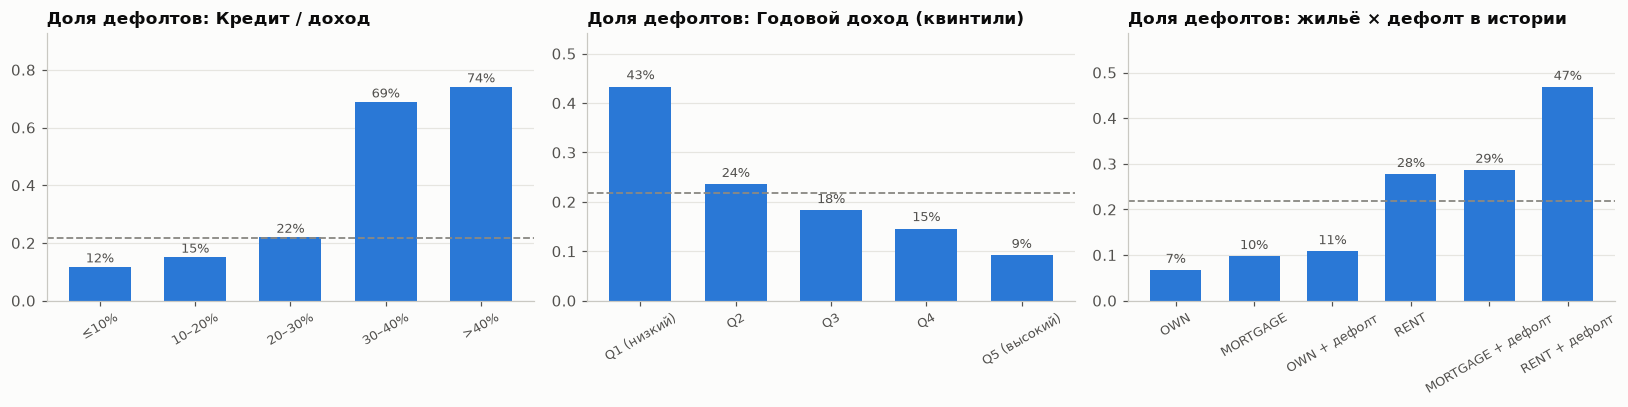

In [82]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
d = df.copy()
groups = [
    ('Кредит / доход', pd.cut(d['loan_percent_income'], [0, 0.1, 0.2, 0.3, 0.4, 1.0], include_lowest=True,
                              labels=['≤10%', '10–20%', '20–30%', '30–40%', '>40%'])),
    ('Годовой доход (квинтили)', pd.qcut(d['person_income'], 5, labels=['Q1 (низкий)', 'Q2', 'Q3', 'Q4', 'Q5 (высокий)'])),
    ('жильё × дефолт в истории', (d['person_home_ownership'].astype(str)
      + pd.Series(np.where(d['cb_person_default_on_file'] == 'Y', ' + дефолт', ''), index=d.index))
     .where(d['person_home_ownership'] != 'OTHER')),
]
for ax, (title, g) in zip(axes, groups):
    r = d.groupby(g, observed=True)[TARGET].mean()
    if title.startswith('жильё'):
        r = r.sort_values()
    ax.bar(r.index.astype(str), r.values, color=C['blue'], width=0.65)
    ax.axhline(d[TARGET].mean(), color=C['muted'], linestyle='--', linewidth=1.2)
    for x_, v in enumerate(r.values):
        ax.text(x_, v + 0.015, f'{v:.0%}', ha='center', fontsize=8.5, color=C['ink2'])
    ax.set_title(f'Доля дефолтов: {title}'); ax.set_ylim(0, min(1.05, r.max() * 1.25)); ax.grid(axis='x', visible=False)
    ax.tick_params(axis='x', rotation=30, labelsize=8.5)
plt.tight_layout(); plt.show()

### 10.2 Наиболее значимые признаки финальной модели
Перестановочная важность на тестовой выборке: насколько падает ROC-AUC, если перемешать значения признака.

,Признак,Падение ROC-AUC,Ст. откл.
person_income,Годовой доход,0.0967,0.0024
loan_percent_income,Кредит / доход,0.0934,0.0024
person_home_ownership,Тип жилья,0.0823,0.0051
loan_grade,Кредитный грейд,0.0665,0.0014
loan_intent,Цель кредита,0.0378,0.0020
loan_int_rate,Процентная ставка,0.0120,0.0014
person_emp_length,Стаж работы,0.0067,0.0008
loan_amnt,Сумма кредита,0.0038,0.0003
cb_person_default_on_file,Дефолт в истории,-0.0000,0.0001


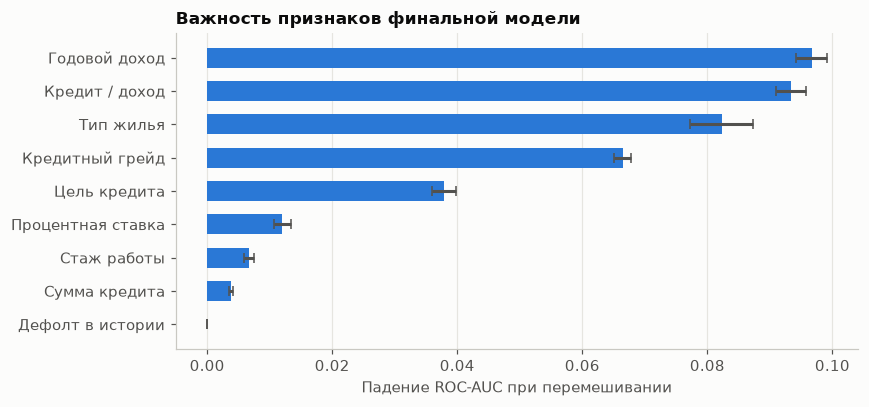

In [83]:
perm_final = permutation_importance(final_model, X_test_raw[SELECTED], y_test, scoring='roc_auc',
                                    n_repeats=10, random_state=RANDOM_STATE)
fi = pd.DataFrame({'Признак': [RU[c] for c in SELECTED], 'Падение ROC-AUC': perm_final.importances_mean,
                   'Ст. откл.': perm_final.importances_std}, index=SELECTED).sort_values('Падение ROC-AUC', ascending=False)
display(fi.round(4))

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(fi['Признак'], fi['Падение ROC-AUC'], xerr=fi['Ст. откл.'], color=C['blue'], height=0.6,
        error_kw={'ecolor': C['ink2'], 'capsize': 3})
ax.invert_yaxis(); ax.grid(axis='y', visible=False)
ax.set_title('Важность признаков финальной модели'); ax.set_xlabel('Падение ROC-AUC при перемешивании')
plt.tight_layout(); plt.show()

### 10.3 Сводка ключевых показателей
Эта ячейка собирает итоговые цифры автоматически - если перезапустить блокнот в другой версии библиотек, значения здесь обновятся.

In [84]:
r20 = capture_rates(y_test, pd_test, 0.2); r50 = capture_rates(y_test, pd_test, 0.5)
s = scen['Фактическая прибыль']
lines = [
    f'Модель: {best_name}',
    f'ROC-AUC (тест) = {auc_test:.4f}; Gini = {gini_test:.4f}; KS = {ks_stat(y_test, pd_test):.4f}',
    f'Порог 0,50: выявлено дефолтных {r50["Доля выявленных дефолтных (TPR)"]:.1%}, ошибочно отклонено надёжных {r50["Доля ошибочно отклонённых надёжных (FPR)"]:.2%}',
    f'Порог 0,20: выявлено дефолтных {r20["Доля выявленных дефолтных (TPR)"]:.1%}, ошибочно отклонено надёжных {r20["Доля ошибочно отклонённых надёжных (FPR)"]:.2%}',
    'Зоны: ' + '; '.join(f'{z} - {zone_table.loc[z, "Доля заявок"]:.1%} заявок, дефолтов {zone_table.loc[z, "Фактическая_доля_дефолтов"]:.1%}' for z in ZONES),
    f'Топ-3 признака: {", ".join(fi["Признак"].head(3))}',
] + [f'{n}: {money(v)} у. е.' for n, v in s.items()]
print('\n'.join(lines))

Модель: Градиентный бустинг (подобранный)
ROC-AUC (тест) = 0.9461; Gini = 0.8922; KS = 0.7565
Порог 0,50: выявлено дефолтных 72.8%, ошибочно отклонено надёжных 0.68%
Порог 0,20: выявлено дефолтных 82.5%, ошибочно отклонено надёжных 7.93%
Зоны: Одобрить - 75.8% заявок, дефолтов 5.0%; Доп. проверка - 7.8% заявок, дефолтов 27.3%; Отклонить - 16.5% заявок, дефолтов 96.8%
Топ-3 признака: Годовой доход, Кредит / доход, Тип жилья
1. Без модели (одобрить всех): -5 417 430 у. е.
2. Консервативный: только PD < 0,20: 3 929 501 у. е.
3. Либеральный: PD ≤ 0,50 (проверка → одобрение): 3 563 064 у. е.
4. Три зоны: в зоне проверки - по знаку EV: 3 947 386 у. е.
5. EV-оптимальный: одобрять при EV > 0: 3 966 343 у. е.
6. Идеальная модель (знает исход, ориентир): 6 231 420 у. е.


### 10.4 Итоговый вывод

**Модель.** Лучший результат показал градиентный бустинг (HistGradientBoosting - ансамбль решающих деревьев) с подобранными гиперпараметрами. На тестовой выборке **ROC-AUC = 0,946, Gini = 0,892, KS = 0,757**. Разрыв между обучающей и тестовой выборками небольшой (AUC 0,964 против 0,946), то есть сильного переобучения нет. Модель хорошо откалибрована: средний предсказанный PD 21,97 % при фактической доле дефолтов 21,87 %, поэтому её вероятности можно напрямую использовать в порогах и в формуле EV. Логистическая регрессия заметно уступает (Gini 0,727) - зависимости в данных нелинейные. Ансамбль Soft Voting (лес + бустинг) не дал выигрыша по сравнению с одним бустингом.

**Выявление дефолтов (п. 8).** При пороге отказа 0,50 модель выявляет **72,8 %** дефолтных заёмщиков и ошибочно отклоняет всего **0,68 %** надёжных. Если считать «не одобренными» все заявки с PD ≥ 0,20 (отказ + доп. проверка), выявляется **82,5 %** дефолтных, а надёжных в эту группу попадает 7,9 %.

**Пороги решения (п. 9).** Автоматически одобряются 75,8 % заявок, дефолтов среди них 5,0 % (в среднем по выборке - 21,9 %). На дополнительную проверку уходит 7,8 % заявок с долей дефолтов 27,3 %. Отклоняется 16,5 % заявок, из них 96,8 % действительно дефолтные.

**Профиль рискованного заёмщика.** Типичный заёмщик из зоны отказа (PD > 0,5):

* **арендует жильё** (81 % в зоне отказа против 44 % в зоне одобрения); аренда в сочетании с дефолтом в прошлом даёт долю дефолтов около 47 %;
* имеет **низкий доход** - медиана 38 тыс. у. е. против 60 тыс. у. е.; в нижнем квинтиле дохода (до 35 тыс.) дефолтов 43 %, в верхнем - 9 %;
* берёт кредит, **слишком большой относительно дохода**: в среднем 28 % годового дохода против 14 %. Порог около 30 % - критический: при доле 20–30 % дефолтов 22 %, при 30–40 % - уже 69 %;
* имеет **плохой грейд D–G** (52 % против 5 %) и, как следствие, высокую ставку (13,5 % против 10,2 %);
* чаще имеет **дефолт в кредитной истории** (35 % против 12 %) и меньший стаж (3,8 против 4,9 года);
* чаще берёт кредит на медицину, рефинансирование долгов или ремонт (доля дефолтов 26–29 %), реже - на образование или бизнес (15–17 %).

**Наиболее значимые признаки.** По перестановочной важности финальной модели: **годовой доход, отношение кредита к доходу, тип жилья, кредитный грейд, цель кредита**. Процентная ставка, стаж и сумма кредита добавляют немного. Дефолт в истории сам по себе информативен (IV = 0,155), но в модели его вклад почти нулевой, потому что эта информация уже учтена в грейде. Возраст и длина кредитной истории неинформативны (IV < 0,02) и исключены без потери качества.

**Экономический эффект (LGD = 60 %, 8 103 заявки тестовой выборки).**

| Сценарий | Одобрено | Фактическая прибыль, у. е. |
|---|---|---|
| Без модели (одобрить всех) | 100 % | −5 417 430 |
| Консервативный: только PD < 0,20 | 75,8 % | 3 929 501 |
| Либеральный: PD ≤ 0,50 | 83,5 % | 3 563 064 |
| Три зоны, в зоне проверки - по знаку EV | 76,0 % | 3 947 386 |
| EV-оптимальный: одобрять при EV > 0 | 71,9 % | 3 966 343 |
| Идеальная модель (ориентир) | 78,1 % | 6 231 420 |

* Выдача кредитов всем без оценки **убыточна**: при 21,9 % дефолтов потери перекрывают процентный доход.
* Модель переводит портфель из убытка в прибыль: улучшение около **9,4 млн у. е.**, то есть примерно 80 % от максимально возможного улучшения (11,6 млн у идеальной модели).
* Одобрение всей зоны проверки (либеральный сценарий) снижает прибыль на 0,37 млн по сравнению с консервативным, потому что доля дефолтов в этой зоне (27 %) выше точки безубыточности (около 15 %).
* Лучший результат дают решения по знаку EV: они учитывают ставку и сумму конкретного кредита, а не только PD.
* Ожидаемая прибыль по модели (Σ EV) близка к фактической (например, 3,68 млн против 3,93 млн у консервативного сценария). Это ещё одно подтверждение того, что прогнозы PD надёжны.

**Чувствительность к LGD.** Без модели прибыль положительна только при LGD = 30 %, а при LGD ≥ 45 % выдача всем убыточна. Сценарии с моделью прибыльны при любом LGD. Чем выше потери при дефолте, тем ниже оптимальный порог одобрения: PD < 0,24 при LGD 45 %, PD < 0,21 при LGD 60 %, PD < 0,14 при LGD 100 %. Значит, порог 0,20 из задания экономически обоснован при LGD около 60 %, а при более высоких потерях его нужно снижать.

**Рекомендация.** Использовать трёхзонную политику: автоматически одобрять заявки с PD < 0,20, отклонять заявки с PD > 0,50, а в зоне 0,20–0,50 одобрять только заявки с положительным EV (или после проверки андеррайтером).

**Ограничения расчёта.** Срок кредита принят равным 1 году, стоимость фондирования и операционные расходы не учтены, LGD задан константой. С их учётом доход $R$ будет меньше, поэтому абсолютная прибыль снизится, а оптимальные пороги сдвинутся вниз.